# Okra Field Disease Dataset: Baseline Benchmark with Leakage-Aware (Group) 5-Fold Cross-Validation

Technical-validation code for the Data Descriptor *"A Field-Based Image Dataset for Automated Recognition of Okra Plant Diseases Using Artificial Intelligence"*.

Two ImageNet-pretrained baselines are fine-tuned for six-class classification:

| Model | Source of ImageNet weights | Input normalisation |
|---|---|---|
| ConvNeXt-Tiny | `tf.keras.applications.ConvNeXtTiny` | built into the Keras model (expects 0-255) |
| MobileNetV3-Large | `tf.keras.applications.MobileNetV3Large` | built into the Keras model (expects 0-255) |

**Leakage-aware evaluation.** Field photographs of the same plant are often near-identical. Section 4.3 groups images whose
64-bit difference hash (dHash) differs by at most `NEAR_DUP_THRESHOLD` bits, and builds the outer 5 folds **and** the inner
validation split with `StratifiedGroupKFold`, so no near-duplicate group is ever split between training and evaluation data.
The fold assignment is identical to `okra_group_aware_5fold_manifest.csv` released with the dataset (checked in Section 4.3).

**Output:** `/kaggle/working/okra_results_groupcv.zip` (all tables, figures and per-fold predictions) and model weights in
`/kaggle/working/okra_models_groupcv/`.

## 1. Dependencies

In [1]:
# Run before importing TensorFlow/Keras. Keep Kaggle's TensorFlow version.
import sys
import subprocess
from importlib.metadata import version

tf_version = version('tensorflow')
tf_major_minor = '.'.join(tf_version.split('.')[:2])
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '--no-deps',
    f'tf-keras~={tf_major_minor}.0'
])
print('Dependencies ready. TensorFlow:', tf_version)

Dependencies ready. TensorFlow: 2.20.0


## 2. Imports and Environment Setup

In [2]:
import os
import sys
import glob
import warnings
import logging
import hashlib
import shutil
import json
import time
import itertools
from multiprocessing import Pool, cpu_count

# Use legacy tf.keras (Keras 2 behaviour) for all models.
if 'tensorflow' in sys.modules and os.environ.get('TF_USE_LEGACY_KERAS') != '1':
    raise RuntimeError('Restart the Kaggle session and run from Section 1 to enable legacy Keras.')
os.environ['TF_USE_LEGACY_KERAS'] = '1'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['AUTOGRAPH_VERBOSITY'] = '0'
os.environ['TF_XLA_FLAGS'] = '--tf_xla_auto_jit=0'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from scipy import stats

import tensorflow as tf
tf.config.optimizer.set_jit(False)

gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as error:
        raise RuntimeError('Restart the session and run Section 2 before any GPU operation.') from error

from absl import logging as absl_logging
tf.get_logger().setLevel(logging.ERROR)
absl_logging.set_verbosity(absl_logging.ERROR)
warnings.filterwarnings('ignore')

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_curve, auc, roc_auc_score
)

from tensorflow.keras.preprocessing.image import load_img
from tensorflow.keras.applications import ConvNeXtTiny, MobileNetV3Large
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

SEED = 42
tf.keras.utils.set_random_seed(SEED)

print('TensorFlow version:', tf.__version__)
print('GPUs available:', gpus)
import sklearn
print('Python', sys.version.split()[0], '| scikit-learn', sklearn.__version__, '| OpenCV', cv2.__version__, '| SciPy', __import__('scipy').__version__)

TensorFlow version: 2.20.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Python 3.13.15 | scikit-learn 1.6.1 | OpenCV 4.14.0 | SciPy 1.16.3


## 3. Configuration

In [3]:
DATASET_PATH    = "/kaggle/input/datasets/mdramjanalimondol/okra-dataset/ORIGINAL IMAGE"
if not os.path.isdir(DATASET_PATH):
    # Kaggle sometimes mounts datasets without the 'datasets/' level; search for the folder instead.
    hits = glob.glob('/kaggle/input/**/ORIGINAL IMAGE', recursive=True)
    if hits:
        DATASET_PATH = hits[0]
# Saved in the notebook output (/kaggle/working): results and model weights.
# Temporary (deleted by the last cell): the dataset copy.
WORKING_DATASET = "/kaggle/temp/okra_dataset"
MODEL_DIR       = "/kaggle/working/okra_models_groupcv"
RESULTS_DIR     = "/kaggle/working/okra_results_groupcv"
SPLIT_DIR       = os.path.join(RESULTS_DIR, "splits")   # small CSVs, kept for reproducibility
for d in ("/kaggle/temp", MODEL_DIR, RESULTS_DIR, SPLIT_DIR):
    os.makedirs(d, exist_ok=True)

IMG_SIZE           = (320, 320)
BATCH_SIZE         = 32
STAGE1_EPOCHS      = 6
STAGE2_EPOCHS      = 14
STAGE3_EPOCHS      = 20
HEAD_LEARNING_RATE = 1e-3
LEARNING_RATE      = 1e-4
DEEP_FINE_TUNE_LR  = 1e-5
WEIGHT_DECAY       = 1e-4
MIN_IMG_SIZE       = 32

N_SPLITS     = 5
SPLIT_SEED   = SEED
INNER_VAL_SPLITS = 8    # inner validation = 1 of 8 group-stratified parts of the training portion (~12.5 %)
VAL_FRACTION = 1 / INNER_VAL_SPLITS   # used for callbacks only (early stopping, LR schedule)

NEAR_DUP_THRESHOLD = 2  # max dHash Hamming distance treated as a near-duplicate (images are grouped, not deleted)

# Optional: path to okra_group_aware_5fold_manifest.csv (from the dataset release) to confirm identical folds.
_ref = glob.glob('/kaggle/input/**/okra_group_aware_5fold_manifest.csv', recursive=True)
REFERENCE_MANIFEST = _ref[0] if _ref else None

MODEL_NAMES = ['ConvNeXt-Tiny', 'MobileNetV3-Large']
METRIC_COLS = ['Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)',
               'F1 (weighted)', 'ROC-AUC (macro OvR)']

print('Dataset               ->', DATASET_PATH)
print('Results (saved)       ->', RESULTS_DIR)
print('Model weights (saved) ->', MODEL_DIR)
print('Dataset copy (temp)   ->', WORKING_DATASET)
print(f'Image {IMG_SIZE}, batch {BATCH_SIZE}, max epochs/fold {STAGE1_EPOCHS + STAGE2_EPOCHS + STAGE3_EPOCHS}')
print(f'Stratified group {N_SPLITS}-fold CV; inner validation fraction {VAL_FRACTION:.1%}')

Dataset               -> /kaggle/input/datasets/mdramjanalimondol/okra-dataset/ORIGINAL IMAGE
Results (saved)       -> /kaggle/working/okra_results_groupcv
Model weights (saved) -> /kaggle/working/okra_models_groupcv
Dataset copy (temp)   -> /kaggle/temp/okra_dataset
Image (320, 320), batch 32, max epochs/fold 40
Stratified group 5-fold CV; inner validation fraction 12.5%


## 4. Dataset Preparation

### 4.1 Copy dataset to the working directory

In [4]:
if not os.path.isdir(DATASET_PATH):
    raise FileNotFoundError(f'Dataset folder not found: {DATASET_PATH}. Add the okra dataset to the notebook.')

source_classes = sorted(
    n for n in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, n)) and not n.startswith('.')
)
if len(source_classes) != 6:
    raise ValueError(f'Expected six class folders; found: {source_classes}')

if not os.path.exists(WORKING_DATASET):
    shutil.copytree(DATASET_PATH, WORKING_DATASET)
    print('Dataset copied to working directory.')
else:
    print('Working dataset already exists, skipping copy.')

IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp'}
source_image_counts = {
    cls: sum(os.path.splitext(f)[1].lower() in IMG_EXT
             for f in os.listdir(os.path.join(DATASET_PATH, cls)))
    for cls in source_classes
}
print('Source classes:', source_classes)
print('Source image counts:', source_image_counts)
print('Source total:', sum(source_image_counts.values()))

Dataset copied to working directory.
Source classes: ['Fruit_Rot', 'Healthy_Leaf', 'Insects_Eaten_Leaf', 'Leaf_Curl', 'Leaf_Spot', 'Yellow_Vein_Mosaic_Virus']
Source image counts: {'Fruit_Rot': 257, 'Healthy_Leaf': 1065, 'Insects_Eaten_Leaf': 745, 'Leaf_Curl': 535, 'Leaf_Spot': 480, 'Yellow_Vein_Mosaic_Virus': 1185}
Source total: 4267


### 4.2 Cleaning and exact-duplicate removal

In [5]:
def check_file(args):
    fpath, min_dim = args
    try:
        img = cv2.imread(fpath)
        if img is None:
            return (fpath, False, None)
        h, w = img.shape[:2]
        if h < min_dim or w < min_dim:
            return (fpath, False, None)
        with open(fpath, 'rb') as f:
            return (fpath, True, hashlib.md5(f.read()).hexdigest())
    except Exception:
        return (fpath, False, None)


def clean_dataset(data_dir, min_dim=MIN_IMG_SIZE):
    files = []
    for cls in sorted(os.listdir(data_dir)):
        cls_path = os.path.join(data_dir, cls)
        if not os.path.isdir(cls_path):
            continue
        for fname in sorted(os.listdir(cls_path)):
            if os.path.splitext(fname)[1].lower() in IMG_EXT:
                files.append(os.path.join(cls_path, fname))

    with Pool(processes=cpu_count()) as pool:
        results = pool.map(check_file, [(fp, min_dim) for fp in files])

    seen, kept, bad, dup = {}, 0, 0, 0
    for fpath, ok, fhash in results:
        if not ok:
            os.remove(fpath); bad += 1
        elif fhash in seen:
            os.remove(fpath); dup += 1
        else:
            seen[fhash] = fpath; kept += 1
    print(f'Kept: {kept} | corrupted/too small removed: {bad} | exact duplicates removed: {dup}')
    return {'kept': kept, 'removed_bad': bad, 'removed_duplicates': dup}


cleaning_stats = clean_dataset(WORKING_DATASET)
with open(os.path.join(RESULTS_DIR, 'cleaning_stats.json'), 'w') as fh:
    json.dump(cleaning_stats, fh, indent=2)

Kept: 4258 | corrupted/too small removed: 0 | exact duplicates removed: 9


### 4.3 Near-duplicate grouping and stratified group 5-fold manifest
A 64-bit dHash is computed for every image. Images within `NEAR_DUP_THRESHOLD` bits of each other are linked, and the connected
components form near-duplicate groups. `StratifiedGroupKFold` then assigns whole groups to folds while keeping class proportions
similar across folds. Nothing is deleted.

In [6]:
def dhash(path, hash_size=8):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (hash_size + 1, hash_size), interpolation=cv2.INTER_AREA)
    bits = (img[:, 1:] > img[:, :-1]).flatten()
    return np.packbits(bits).view(np.uint64)[0]


def near_duplicate_pairs(hashes, threshold):
    """All index pairs (i, j, distance) whose dHash Hamming distance is <= threshold."""
    pairs = []
    for i in range(len(hashes) - 1):
        xor = np.ascontiguousarray(hashes[i] ^ hashes[i + 1:])
        dist = np.unpackbits(xor.view(np.uint8).reshape(-1, 8), axis=1).sum(axis=1)
        for j in np.where(dist <= threshold)[0]:
            pairs.append((i, i + 1 + j, int(dist[j])))
    return pairs


def group_ids_from_pairs(n, pairs):
    """Connected components of the near-duplicate graph (union-find).
    Groups are numbered in order of their first member in the sorted file list."""
    parent = list(range(n))

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    for a, b, _ in pairs:
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[max(ra, rb)] = min(ra, rb)
    roots, ids = {}, np.zeros(n, dtype=np.int64)
    for i in range(n):
        r = find(i)
        if r not in roots:
            roots[r] = len(roots)
        ids[i] = roots[r]
    return ids


def prepare_group_aware_folds():
    records = []
    class_names = sorted(
        n for n in os.listdir(WORKING_DATASET)
        if os.path.isdir(os.path.join(WORKING_DATASET, n)) and not n.startswith('.')
    )
    if class_names != source_classes:
        raise ValueError('Working and source class folders differ. Use a fresh working directory.')

    for cls in class_names:
        cls_dir = os.path.join(WORKING_DATASET, cls)
        for fname in sorted(os.listdir(cls_dir)):
            if os.path.splitext(fname)[1].lower() in IMG_EXT:
                path = os.path.join(cls_dir, fname)
                with open(path, 'rb') as f:
                    md5 = hashlib.md5(f.read()).hexdigest()
                records.append({'relative_path': os.path.join(cls, fname), 'Class': cls, 'md5': md5})

    frame = pd.DataFrame(records).sort_values('relative_path').reset_index(drop=True)
    if frame['md5'].duplicated().any():
        raise RuntimeError('Exact duplicates remain. Rerun Section 4.2 on a fresh working dataset.')

    # 1) Near-duplicate groups from the 64-bit dHash (Hamming distance <= NEAR_DUP_THRESHOLD).
    hashes = np.array([dhash(os.path.join(WORKING_DATASET, p)) for p in frame['relative_path']], dtype=np.uint64)
    pairs = near_duplicate_pairs(hashes, NEAR_DUP_THRESHOLD)
    frame['group_id'] = group_ids_from_pairs(len(frame), pairs)
    frame['group_size'] = frame.groupby('group_id')['group_id'].transform('size')

    # 2) Stratified GROUP 5-fold: every near-duplicate group stays inside one fold.
    splitter = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SPLIT_SEED)
    fold_ids = np.zeros(len(frame), dtype=np.int64)
    for fold, (_, test_idx) in enumerate(splitter.split(frame, frame['Class'], groups=frame['group_id']), start=1):
        fold_ids[test_idx] = fold
    frame['Fold'] = fold_ids

    if (frame.groupby('group_id')['Fold'].nunique() > 1).any():
        raise RuntimeError('A near-duplicate group spans more than one fold.')
    cross = sum(frame.at[a, 'Fold'] != frame.at[b, 'Fold'] for a, b, _ in pairs)
    print(f'Near-duplicate pairs: {len(pairs)} | groups: {frame.group_id.nunique()} '
          f'(multi-image: {(frame.drop_duplicates("group_id").group_size > 1).sum()}) | pairs across folds: {cross}')

    # 3) Optional: confirm the assignment matches the manifest released with the dataset.
    if REFERENCE_MANIFEST and os.path.exists(REFERENCE_MANIFEST):
        ref = pd.read_csv(REFERENCE_MANIFEST).set_index('relative_path')
        same = frame.set_index('relative_path')['Fold'].eq(ref['GroupFold'].reindex(frame['relative_path'])).all()
        print('Matches released group-aware manifest:', bool(same))

    cols = ['relative_path', 'Class', 'md5', 'group_id', 'group_size', 'Fold']
    frame = frame[cols]
    manifest_path = os.path.join(SPLIT_DIR, 'group_aware_5fold_manifest.csv')
    if os.path.exists(manifest_path):
        saved = pd.read_csv(manifest_path, dtype={'relative_path': str, 'Class': str, 'md5': str,
                                                  'group_id': int, 'group_size': int, 'Fold': int})
        if not saved.equals(frame):
            raise RuntimeError('Dataset or fold assignment changed. Use fresh SPLIT_DIR/results/model directories.')
        print('Reusing verified manifest.')
    else:
        frame.to_csv(manifest_path, index=False)
        print('Manifest created.')

    print('Usable images after cleaning:', len(frame))
    print('Held-out (test) images per class in each fold:')
    print(pd.crosstab(frame['Class'], frame['Fold']))
    return frame


fold_manifest = prepare_group_aware_folds()
CLASS_NAMES = source_classes
NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_INDEX = {n: i for i, n in enumerate(CLASS_NAMES)}

Near-duplicate pairs: 3234 | groups: 2191 (multi-image: 1250) | pairs across folds: 0
Manifest created.
Usable images after cleaning: 4258
Held-out (test) images per class in each fold:
Fold                        1    2    3    4    5
Class                                            
Fruit_Rot                  52   47   59   49   50
Healthy_Leaf              237  205  219  191  213
Insects_Eaten_Leaf        152  147  146  149  150
Leaf_Curl                  95   92  134  106  104
Leaf_Spot                  86   92  101   99  101
Yellow_Vein_Mosaic_Virus  235  232  226  238  251


### 4.4 Near-duplicate check (verification)
Recomputes the near-duplicate pairs and confirms that none of them falls in different folds.

In [7]:
def dhash(path, hash_size=8):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (hash_size + 1, hash_size), interpolation=cv2.INTER_AREA)
    bits = (img[:, 1:] > img[:, :-1]).flatten()
    return np.packbits(bits).view(np.uint64)[0]


paths = [os.path.join(WORKING_DATASET, p) for p in fold_manifest['relative_path']]
hashes = np.array([dhash(p) for p in paths], dtype=np.uint64)

pairs = []
for i in range(len(hashes) - 1):
    xor = np.ascontiguousarray(hashes[i] ^ hashes[i + 1:])
    dist = np.unpackbits(xor.view(np.uint8).reshape(-1, 8), axis=1).sum(axis=1)
    for j in np.where(dist <= NEAR_DUP_THRESHOLD)[0]:
        pairs.append((i, i + 1 + j, int(dist[j])))

near = pd.DataFrame([{
    'image_a': fold_manifest.loc[a, 'relative_path'], 'image_b': fold_manifest.loc[b, 'relative_path'],
    'class_a': fold_manifest.loc[a, 'Class'], 'class_b': fold_manifest.loc[b, 'Class'],
    'fold_a': int(fold_manifest.loc[a, 'Fold']), 'fold_b': int(fold_manifest.loc[b, 'Fold']),
    'hamming_distance': d
} for a, b, d in pairs])

near.to_csv(os.path.join(RESULTS_DIR, 'near_duplicate_pairs.csv'), index=False)
if len(near):
    print(f'Near-duplicate pairs (distance <= {NEAR_DUP_THRESHOLD}): {len(near)}')
    print('  same class      :', int((near.class_a == near.class_b).sum()))
    print('  different folds :', int((near.fold_a != near.fold_b).sum()), '(must be 0)')
    assert int((near.fold_a != near.fold_b).sum()) == 0
else:
    print('No near-duplicate pairs found at this threshold.')

Near-duplicate pairs (distance <= 2): 3234
  same class      : 3234
  different folds : 0 (must be 0)


## 5. Data Pipeline (train / inner-validation / held-out test)

In [8]:
AUTOTUNE = tf.data.AUTOTUNE


def _decode_resize(path, label):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE, antialias=True)
    image = tf.cast(image, tf.float32)
    return image, tf.one_hot(label, depth=NUM_CLASSES)


def _rows_to_arrays(rows):
    paths = [os.path.join(WORKING_DATASET, p) for p in rows['relative_path']]
    labels = rows['Class'].map(CLASS_TO_INDEX).to_numpy(dtype=np.int32)
    return paths, labels


def make_fold_datasets(fold):
    """Held-out fold = test. The rest is split (stratified, group-aware) into train and inner validation."""
    test_rows = fold_manifest[fold_manifest['Fold'] == fold].reset_index(drop=True)
    train_all = fold_manifest[fold_manifest['Fold'] != fold].reset_index(drop=True)

    # Inner validation split is also group-aware: near-duplicates never straddle train / validation.
    inner = StratifiedGroupKFold(n_splits=INNER_VAL_SPLITS, shuffle=True, random_state=SEED + fold)
    tr_idx, va_idx = next(inner.split(train_all, train_all['Class'], groups=train_all['group_id']))
    train_rows = train_all.iloc[np.sort(tr_idx)].reset_index(drop=True)
    val_rows = train_all.iloc[np.sort(va_idx)].reset_index(drop=True)

    assign_path = os.path.join(SPLIT_DIR, f'fold{fold}_split_assignment.csv')
    if not os.path.exists(assign_path):
        pd.concat([
            train_rows.assign(Role='train'), val_rows.assign(Role='validation'), test_rows.assign(Role='test')
        ])[['relative_path', 'Class', 'Role']].to_csv(assign_path, index=False)

    tr_p, tr_y = _rows_to_arrays(train_rows)
    va_p, va_y = _rows_to_arrays(val_rows)
    te_p, te_y = _rows_to_arrays(test_rows)

    train_ds = tf.data.Dataset.from_tensor_slices((tr_p, tr_y))
    train_ds = train_ds.shuffle(len(tr_p), seed=SEED + fold, reshuffle_each_iteration=True)
    train_ds = train_ds.map(_decode_resize, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

    val_ds = tf.data.Dataset.from_tensor_slices((va_p, va_y))
    val_ds = val_ds.map(_decode_resize, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

    test_ds = tf.data.Dataset.from_tensor_slices((te_p, te_y))
    test_ds = test_ds.map(_decode_resize, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

    weights = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=tr_y)  # from train only
    info = {
        'class_weights': {i: float(w) for i, w in enumerate(weights)},
        'n_train': len(tr_p), 'n_val': len(va_p), 'n_test': len(te_p),
        'test_rows': test_rows,
    }
    return train_ds, val_ds, test_ds, info


_, _, _, preview = make_fold_datasets(1)
print(f"Fold 1 -> train {preview['n_train']} | inner validation {preview['n_val']} | held-out test {preview['n_test']}")
print('Fold 1 class weights:', {CLASS_NAMES[k]: round(v, 3) for k, v in preview['class_weights'].items()})

I0000 00:00:1793387056.211777      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793387056.217193      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Fold 1 -> train 2982 | inner validation 419 | held-out test 857
Fold 1 class weights: {'Fruit_Rot': 2.84, 'Healthy_Leaf': 0.676, 'Insects_Eaten_Leaf': 0.948, 'Leaf_Curl': 1.284, 'Leaf_Spot': 1.47, 'Yellow_Vein_Mosaic_Virus': 0.604}


## 6. Dataset Exploration

,Class,Source images,After cleaning
0,Fruit_Rot,257,257
1,Healthy_Leaf,1065,1065
2,Insects_Eaten_Leaf,745,744
3,Leaf_Curl,535,531
4,Leaf_Spot,480,479
5,Yellow_Vein_Mosaic_Virus,1185,1182
6,TOTAL,4267,4258


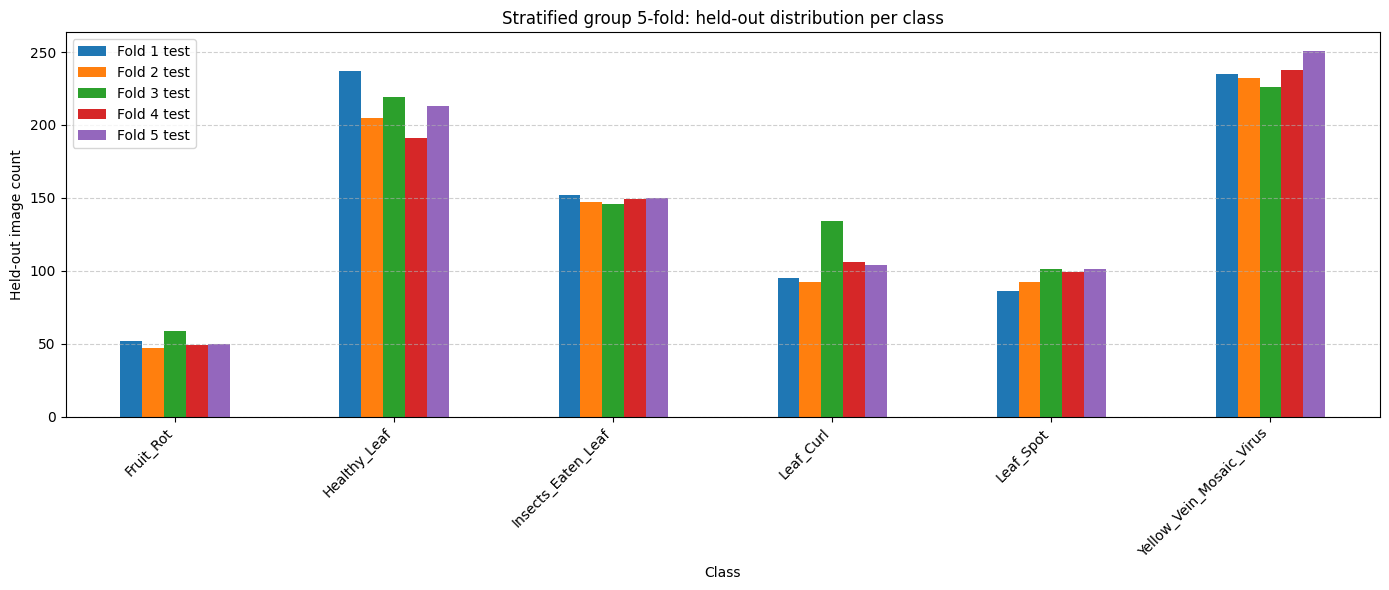

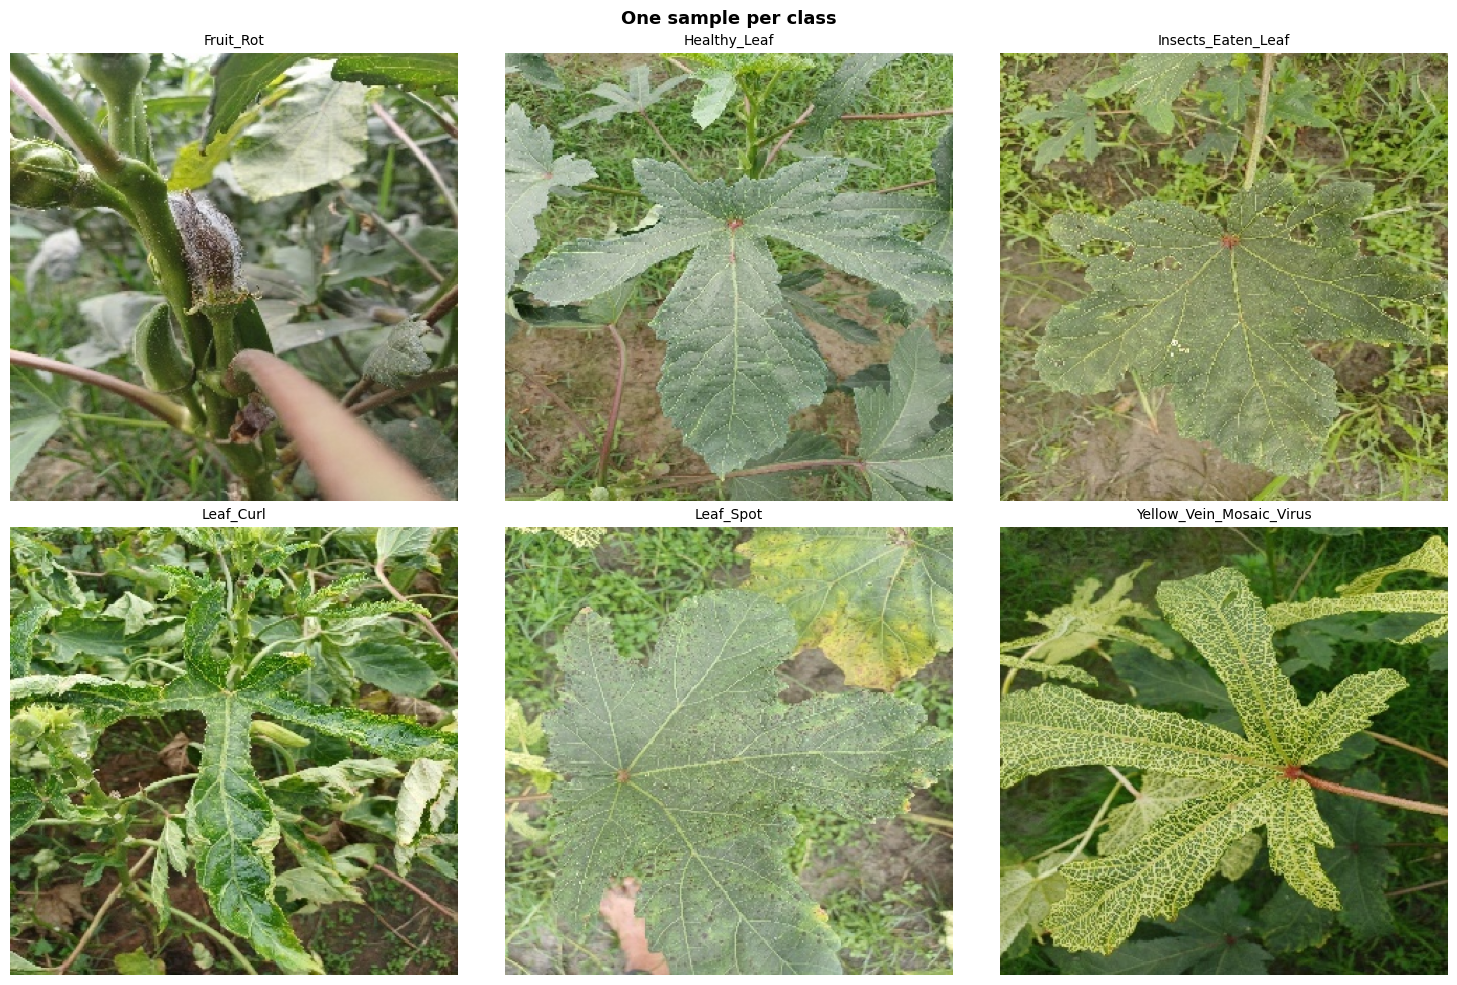

,Setting,Value
0,Models,"ConvNeXt-Tiny, MobileNetV3-Large"
1,Input size,"(320, 320)"
2,Batch size,32
3,Cross-validation,Stratified group 5-fold (dHash near-duplicate ...
4,Inner validation split,"12.5% of training portion (stratified, group-a..."
5,Max epochs / fold,40
6,Stage 1 (frozen backbone) LR / epochs,0.001 / 6
7,Stage 2 (top 30 % unfrozen) LR / epochs,0.0001 / 14
8,Stage 3 (top 70 % unfrozen) LR / epochs,1e-05 / 20
9,Optimizer,AdamW (weight decay 0.0001)


,"Augmentation (training only, on GPU)",Setting
0,Horizontal + vertical flip,random
1,Rotation,+/- 15 deg
2,Zoom,+/- 10 %
3,Translation,"+/- 5 % (x, y)"
4,Contrast,+/- 10 %


In [9]:
cleaned_counts = fold_manifest['Class'].value_counts().reindex(CLASS_NAMES)
df_counts = pd.DataFrame({
    'Class': CLASS_NAMES,
    'Source images': [source_image_counts[c] for c in CLASS_NAMES],
    'After cleaning': cleaned_counts.values,
})
df_counts.loc[len(df_counts)] = ['TOTAL', df_counts['Source images'].sum(), df_counts['After cleaning'].sum()]
display(df_counts)
df_counts.to_csv(os.path.join(RESULTS_DIR, 'dataset_class_counts.csv'), index=False)

fold_counts = pd.crosstab(fold_manifest['Class'], fold_manifest['Fold']).reindex(CLASS_NAMES)
fold_counts.columns = [f'Fold {c} test' for c in fold_counts.columns]
fold_counts.to_csv(os.path.join(RESULTS_DIR, 'dataset_fold_distribution.csv'))

fig, ax = plt.subplots(figsize=(14, 6))
fold_counts.plot(kind='bar', ax=ax)
ax.set_xlabel('Class'); ax.set_ylabel('Held-out image count')
ax.set_title('Stratified group 5-fold: held-out distribution per class')
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right')
ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'dataset_distribution.png'), dpi=300)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for i, cls in enumerate(CLASS_NAMES):
    first = fold_manifest[fold_manifest['Class'] == cls]['relative_path'].iloc[0]
    axes[i // 3, i % 3].imshow(load_img(os.path.join(WORKING_DATASET, first), target_size=IMG_SIZE))
    axes[i // 3, i % 3].set_title(cls, fontsize=10)
    axes[i // 3, i % 3].axis('off')
plt.suptitle('One sample per class', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'sample_images_grid.png'), dpi=300)
plt.show()

df_hyper = pd.DataFrame({
    'Setting': ['Models', 'Input size', 'Batch size', 'Cross-validation', 'Inner validation split', 'Max epochs / fold',
                'Stage 1 (frozen backbone) LR / epochs', 'Stage 2 (top 30 % unfrozen) LR / epochs',
                'Stage 3 (top 70 % unfrozen) LR / epochs', 'Optimizer', 'Loss', 'Class weighting',
                'Classification head', 'Early stopping patience (stage 1/2/3)', 'LR reduction',
                'Pretrained weights', 'Preprocessing', 'Random seed'],
    'Value': [', '.join(MODEL_NAMES), str(IMG_SIZE), str(BATCH_SIZE), f'Stratified group {N_SPLITS}-fold (dHash near-duplicate groups, distance <= {NEAR_DUP_THRESHOLD})',
              f'{VAL_FRACTION:.1%} of training portion (stratified, group-aware)',
              str(STAGE1_EPOCHS + STAGE2_EPOCHS + STAGE3_EPOCHS),
              f'{HEAD_LEARNING_RATE} / {STAGE1_EPOCHS}', f'{LEARNING_RATE} / {STAGE2_EPOCHS}', f'{DEEP_FINE_TUNE_LR} / {STAGE3_EPOCHS}',
              f'AdamW (weight decay {WEIGHT_DECAY})', 'Categorical cross-entropy', 'Balanced, computed on training split of each fold',
              'GlobalAveragePooling -> Dense(512, ReLU) -> Dropout(0.5) -> Dense(6, softmax)', '4 / 6 / 8',
              'ReduceLROnPlateau (val_loss, factor 0.5, patience 3)',
              'ImageNet (Keras Applications)',
              'Resize 320x320 (antialias); model-specific input normalisation', str(SEED)]
})
df_aug = pd.DataFrame({
    'Augmentation (training only, on GPU)': ['Horizontal + vertical flip', 'Rotation', 'Zoom', 'Translation', 'Contrast'],
    'Setting': ['random', '+/- 15 deg', '+/- 10 %', '+/- 5 % (x, y)', '+/- 10 %']
})
display(df_hyper); display(df_aug)
df_hyper.to_csv(os.path.join(RESULTS_DIR, 'hyperparameters.csv'), index=False)
df_aug.to_csv(os.path.join(RESULTS_DIR, 'augmentation_config.csv'), index=False)

## 7. Model Builder and Helpers

In [10]:
def build_cnn_model(base_fn, preprocess_fn=None, img_size=IMG_SIZE, num_classes=NUM_CLASSES):
    inp = Input(shape=img_size + (3,), name='input')
    x = tf.keras.layers.RandomFlip('horizontal_and_vertical', name='aug_flip')(inp)
    x = tf.keras.layers.RandomRotation(15 / 360.0, name='aug_rotation')(x)
    x = tf.keras.layers.RandomZoom(0.10, name='aug_zoom')(x)
    x = tf.keras.layers.RandomTranslation(0.05, 0.05, name='aug_translation')(x)
    x = tf.keras.layers.RandomContrast(0.10, name='aug_contrast')(x)
    if preprocess_fn:
        x = tf.keras.layers.Lambda(preprocess_fn, name='preprocess')(x)

    base = base_fn(weights='imagenet', include_top=False, input_shape=img_size + (3,))
    base.trainable = False
    x = base(x, training=False)          # BatchNorm stays in inference mode during fine-tuning
    x = GlobalAveragePooling2D()(x)
    x = Dense(512, activation='relu')(x)
    x = Dropout(0.5)(x)
    out = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=inp, outputs=out)
    model._okra_backbone = base
    return model


BUILD_FNS = {
    # Both Keras models include their own input preprocessing and expect 0-255 input.
    'ConvNeXt-Tiny':     lambda: build_cnn_model(ConvNeXtTiny, preprocess_fn=None),
    # Keras logs a warning that MobileNetV3 ImageNet weights are for 224x224; the conv weights work at 320x320.
    'MobileNetV3-Large': lambda: build_cnn_model(MobileNetV3Large, preprocess_fn=None),
}


def get_okra_backbone(model):
    if hasattr(model, '_okra_backbone'):
        return model._okra_backbone
    for layer in model.layers:
        if isinstance(layer, tf.keras.Model):
            return layer
    raise ValueError('Backbone not found.')


def set_backbone_trainable_fraction(model, fraction):
    base = get_okra_backbone(model)
    if fraction <= 0:
        base.trainable = False
        return
    base.trainable = True
    train_from = int(len(base.layers) * (1.0 - fraction))
    for i, layer in enumerate(base.layers):
        layer.trainable = (i >= train_from)
    n = sum(l.trainable for l in base.layers)
    print(f'  Backbone trainable layers: {n}/{len(base.layers)} ({fraction:.0%} target)')


def save_json_atomic(path, data, indent=None):
    tmp = f'{path}.tmp'
    with open(tmp, 'w', encoding='utf-8') as fh:
        json.dump(data, fh, indent=indent, default=lambda v: v.item() if isinstance(v, np.generic) else str(v))
        fh.flush(); os.fsync(fh.fileno())
    os.replace(tmp, path)


def plot_training_history(history, title, save_name):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
    ax1.plot(history['accuracy'], label='Train'); ax1.plot(history['val_accuracy'], label='Validation')
    ax1.set_title(f'{title} - Accuracy'); ax1.set_xlabel('Epoch'); ax1.set_ylabel('Accuracy')
    ax2.plot(history['loss'], label='Train'); ax2.plot(history['val_loss'], label='Validation')
    ax2.set_title(f'{title} - Loss'); ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss')
    for ax in (ax1, ax2):
        ax.legend(); ax.grid(linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, save_name), dpi=300)
    plt.show(); plt.close()


def evaluate_fold(model, test_ds, test_rows, model_name, fold):
    """Single evaluation on the held-out fold. Saves predictions, report and returns metrics."""
    probs = model.predict(test_ds, verbose=0).astype(np.float64)
    probs = probs / probs.sum(axis=1, keepdims=True)
    y_true = test_rows['Class'].map(CLASS_TO_INDEX).to_numpy()
    y_pred = probs.argmax(axis=1)

    report = classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                                   target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(os.path.join(RESULTS_DIR, f'{model_name}_fold{fold}_classification_report.csv'))

    macro_auc = roc_auc_score(y_true, probs, multi_class='ovr', average='macro', labels=np.arange(NUM_CLASSES))

    pred_df = pd.DataFrame({'relative_path': test_rows['relative_path'], 'true': y_true, 'pred': y_pred})
    for i, cls in enumerate(CLASS_NAMES):
        pred_df[f'p_{cls}'] = probs[:, i]
    return pred_df, {
        'Model': model_name, 'Fold': fold,
        'Accuracy': float(report['accuracy']),
        'Precision (macro)': float(report['macro avg']['precision']),
        'Recall (macro)': float(report['macro avg']['recall']),
        'F1 (macro)': float(report['macro avg']['f1-score']),
        'F1 (weighted)': float(report['weighted avg']['f1-score']),
        'ROC-AUC (macro OvR)': float(macro_auc),
    }


# Quick build test of both models (CPU, no training) so problems show up before the long runs.
for _name, _fn in BUILD_FNS.items():
    with tf.device('/CPU:0'):
        _m = _fn()
    _b = get_okra_backbone(_m)
    print(f'{_name:18s} total params {_m.count_params() / 1e6:6.2f} M | backbone layers {len(_b.layers):4d} | '
          f'feature map {tuple(_b.output_shape[1:])}')
    del _m, _b
tf.keras.backend.clear_session()

111650432/111650432 [==============================] - 0s 0us/step
ConvNeXt-Tiny      total params  28.22 M | backbone layers  151 | feature map (10, 10, 768)
12683000/12683000 [==============================] - 0s 0us/step
MobileNetV3-Large  total params   3.49 M | backbone layers  263 | feature map (10, 10, 960)


## 8. Training Infrastructure

In [11]:
strategy = tf.distribute.MirroredStrategy()
print('Replicas in sync:', strategy.num_replicas_in_sync, '| devices:', strategy.extended.worker_devices)
if len(gpus) < 2:
    print('Only one GPU visible. Select Kaggle "GPU T4 x2" for dual-GPU training.')


class PersistentBestCheckpoint(tf.keras.callbacks.Callback):
    """Keeps the best-val_loss weights (inner validation set) across all three fine-tuning stages."""
    def __init__(self, path):
        super().__init__()
        self.path, self.best, self.best_weights = path, np.inf, None

    def on_epoch_end(self, epoch, logs=None):
        cur = (logs or {}).get('val_loss')
        if cur is not None and np.isfinite(cur) and cur < self.best:
            self.best = float(cur)
            self.best_weights = [np.array(w, copy=True) for w in self.model.get_weights()]
            self.model.save_weights(self.path)

    def restore_best_weights(self):
        if self.best_weights is None:
            raise RuntimeError('No best weights available.')
        self.model.set_weights(self.best_weights)


def _stage_callbacks(ckpt, patience):
    return [
        ckpt,
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7, verbose=1),
        EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=False, verbose=1),
    ]


def _compile_for_stage(model, lr):
    with strategy.scope():
        model.compile(optimizer=AdamW(learning_rate=lr, weight_decay=WEIGHT_DECAY),
                      loss='categorical_crossentropy', metrics=['accuracy'], jit_compile=False)


def _merge_history(target, h):
    for k, v in h.history.items():
        target.setdefault(k, []).extend([float(x) for x in v])


def fold_paths(model_name, fold):
    return {
        'weights': os.path.join(MODEL_DIR, f'{model_name}_fold{fold}_best.weights.h5'),
        'history': os.path.join(RESULTS_DIR, f'{model_name}_fold{fold}_history_data.json'),
        'metrics': os.path.join(RESULTS_DIR, f'{model_name}_fold{fold}_metrics.json'),
        'preds':   os.path.join(RESULTS_DIR, f'{model_name}_fold{fold}_predictions.csv'),
    }


STAGES = [  # (id, backbone fraction, LR, max epochs, patience, label)
    (1, 0.00, HEAD_LEARNING_RATE, STAGE1_EPOCHS, 4, 'frozen backbone (head only)'),
    (2, 0.30, LEARNING_RATE,      STAGE2_EPOCHS, 6, 'fine-tune top 30 % of backbone'),
    (3, 0.70, DEEP_FINE_TUNE_LR,  STAGE3_EPOCHS, 8, 'fine-tune top 70 % of backbone'),
]


def train_and_evaluate(model_name):
    build_fn = BUILD_FNS[model_name]
    print(f'\nModel: {model_name} | Stratified group {N_SPLITS}-fold CV | inner validation {VAL_FRACTION:.1%}')
    rows = []

    for fold in range(1, N_SPLITS + 1):
        p = fold_paths(model_name, fold)
        if all(os.path.exists(p[k]) for k in ('weights', 'metrics', 'preds')):
            with open(p['metrics'], encoding='utf-8') as fh:
                rows.append(json.load(fh))
            print(f'Fold {fold}: completed results found, skipping.')
            continue

        print('\n' + '=' * 72)
        print(f'{model_name} - Fold {fold}/{N_SPLITS}')
        print('=' * 72)
        tf.keras.utils.set_random_seed(SEED + fold)
        train_ds, val_ds, test_ds, info = make_fold_datasets(fold)
        print(f"Train {info['n_train']} | inner validation {info['n_val']} | held-out test {info['n_test']}")

        with strategy.scope():
            model = build_fn()

        ckpt = PersistentBestCheckpoint(p['weights'])
        history = {}
        t0 = time.time()
        for sid, frac, lr, epochs, patience, label in STAGES:
            print(f'\nStage {sid}/3: {label}')
            set_backbone_trainable_fraction(model, frac)
            _compile_for_stage(model, lr)
            h = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                          callbacks=_stage_callbacks(ckpt, patience),
                          class_weight=info['class_weights'], verbose=2)
            _merge_history(history, h)
            ckpt.restore_best_weights()   # continue every stage from the best inner-validation weights
        train_minutes = (time.time() - t0) / 60
        print(f'Fold {fold} training finished in {train_minutes:.1f} min.')

        save_json_atomic(p['history'], history)
        plot_training_history(history, f'{model_name} fold {fold}', f'{model_name}_fold{fold}_history.png')

        # Single evaluation on the untouched held-out fold.
        pred_df, metrics = evaluate_fold(model, test_ds, info['test_rows'], model_name, fold)
        metrics.update({
            'Train images': info['n_train'], 'Validation images': info['n_val'], 'Test images': info['n_test'],
            'Epochs run': len(history['loss']), 'Best inner val loss': ckpt.best,
            'Train time (min)': train_minutes,
        })
        pred_df.to_csv(p['preds'], index=False)
        save_json_atomic(p['metrics'], metrics, indent=2)
        rows.append(metrics)
        print(f"Fold {fold} | Acc {metrics['Accuracy']:.4f} | F1 {metrics['F1 (macro)']:.4f} | AUC {metrics['ROC-AUC (macro OvR)']:.4f}")

        del model
        tf.keras.backend.clear_session()

    df = pd.DataFrame(rows).sort_values('Fold')
    df.to_csv(os.path.join(RESULTS_DIR, f'{model_name}_5fold_metrics.csv'), index=False)
    print(f'\n{model_name} summary (mean +/- SD over {N_SPLITS} folds)')
    for c in METRIC_COLS:
        print(f'  {c:22s}: {df[c].mean():.4f} +/- {df[c].std(ddof=1):.4f}')
    return df

Replicas in sync: 2 | devices: ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')


## 9. Model Training
Each cell trains 5 folds. Completed folds are skipped automatically on re-run.

### 9.1 ConvNeXt-Tiny


Model: ConvNeXt-Tiny | Stratified group 5-fold CV | inner validation 12.5%

ConvNeXt-Tiny - Fold 1/5
Train 2982 | inner validation 419 | held-out test 857

Stage 1/3: frozen backbone (head only)
Epoch 1/6


I0000 00:00:1793387092.885013      90 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


94/94 - 64s - loss: 0.9139 - accuracy: 0.6489 - val_loss: 0.6278 - val_accuracy: 0.7589 - lr: 0.0010 - 64s/epoch - 676ms/step
Epoch 2/6
94/94 - 27s - loss: 0.5426 - accuracy: 0.7793 - val_loss: 0.6577 - val_accuracy: 0.7542 - lr: 0.0010 - 27s/epoch - 293ms/step
Epoch 3/6
94/94 - 28s - loss: 0.4606 - accuracy: 0.8072 - val_loss: 0.6774 - val_accuracy: 0.7494 - lr: 0.0010 - 28s/epoch - 300ms/step
Epoch 4/6
94/94 - 30s - loss: 0.4091 - accuracy: 0.8364 - val_loss: 0.5770 - val_accuracy: 0.7924 - lr: 0.0010 - 30s/epoch - 317ms/step
Epoch 5/6
94/94 - 30s - loss: 0.3803 - accuracy: 0.8441 - val_loss: 0.5592 - val_accuracy: 0.8067 - lr: 0.0010 - 30s/epoch - 316ms/step
Epoch 6/6
94/94 - 29s - loss: 0.3573 - accuracy: 0.8514 - val_loss: 0.5851 - val_accuracy: 0.7780 - lr: 0.0010 - 29s/epoch - 305ms/step

Stage 2/3: fine-tune top 30 % of backbone
  Backbone trainable layers: 46/151 (30% target)
Epoch 1/14
94/94 - 76s - loss: 0.3004 - accuracy: 0.8776 - val_loss: 0.5177 - val_accuracy: 0.8329 - l

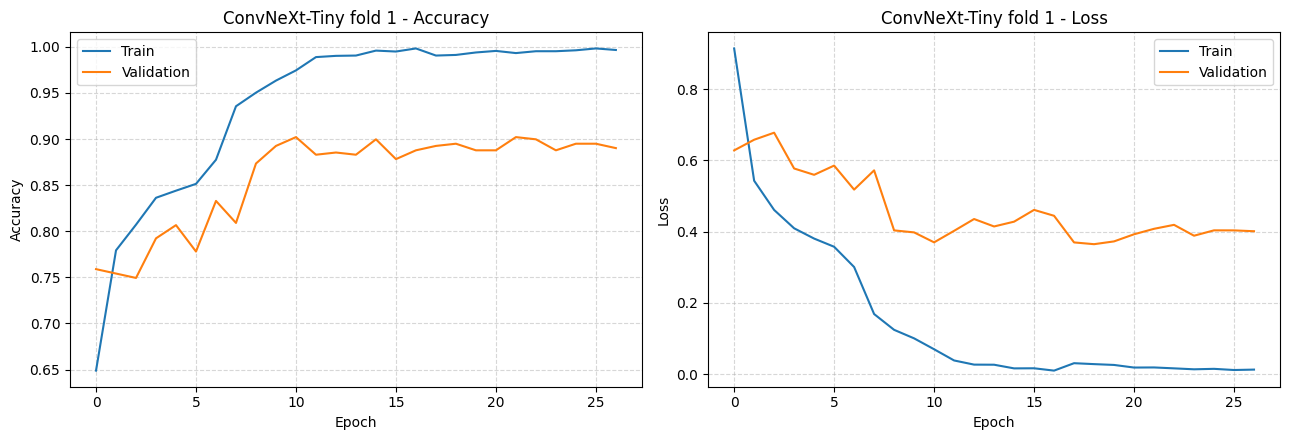

Fold 1 | Acc 0.9172 | F1 0.9123 | AUC 0.9915

ConvNeXt-Tiny - Fold 2/5
Train 3004 | inner validation 439 | held-out test 815

Stage 1/3: frozen backbone (head only)
Epoch 1/6
94/94 - 62s - loss: 0.8803 - accuracy: 0.6628 - val_loss: 0.7348 - val_accuracy: 0.7403 - lr: 0.0010 - 62s/epoch - 656ms/step
Epoch 2/6
94/94 - 30s - loss: 0.5428 - accuracy: 0.7803 - val_loss: 0.6345 - val_accuracy: 0.7472 - lr: 0.0010 - 30s/epoch - 322ms/step
Epoch 3/6
94/94 - 30s - loss: 0.4770 - accuracy: 0.8036 - val_loss: 0.4963 - val_accuracy: 0.8041 - lr: 0.0010 - 30s/epoch - 317ms/step
Epoch 4/6
94/94 - 29s - loss: 0.4375 - accuracy: 0.8196 - val_loss: 0.6576 - val_accuracy: 0.7221 - lr: 0.0010 - 29s/epoch - 310ms/step
Epoch 5/6
94/94 - 30s - loss: 0.3893 - accuracy: 0.8439 - val_loss: 0.4722 - val_accuracy: 0.8178 - lr: 0.0010 - 30s/epoch - 319ms/step
Epoch 6/6
94/94 - 29s - loss: 0.3701 - accuracy: 0.8525 - val_loss: 0.4730 - val_accuracy: 0.8200 - lr: 0.0010 - 29s/epoch - 310ms/step

Stage 2/3: fine-tu

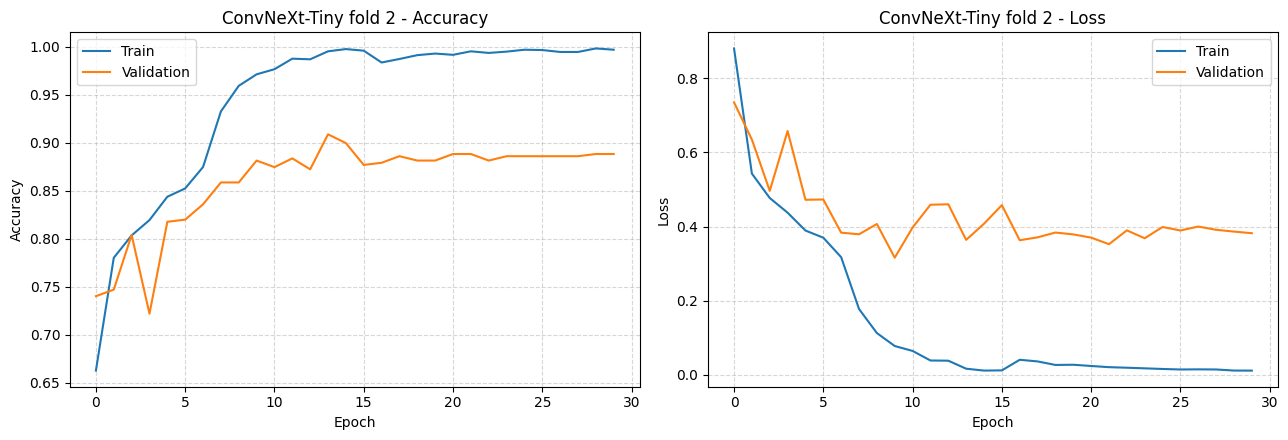

Fold 2 | Acc 0.9166 | F1 0.9145 | AUC 0.9923

ConvNeXt-Tiny - Fold 3/5
Train 2935 | inner validation 438 | held-out test 885

Stage 1/3: frozen backbone (head only)
Epoch 1/6
92/92 - 61s - loss: 0.9093 - accuracy: 0.6572 - val_loss: 0.7377 - val_accuracy: 0.7123 - lr: 0.0010 - 61s/epoch - 660ms/step
Epoch 2/6
92/92 - 29s - loss: 0.5671 - accuracy: 0.7748 - val_loss: 0.7699 - val_accuracy: 0.6735 - lr: 0.0010 - 29s/epoch - 313ms/step
Epoch 3/6
92/92 - 29s - loss: 0.4941 - accuracy: 0.7986 - val_loss: 0.5235 - val_accuracy: 0.7763 - lr: 0.0010 - 29s/epoch - 320ms/step
Epoch 4/6
92/92 - 29s - loss: 0.4383 - accuracy: 0.8235 - val_loss: 0.5015 - val_accuracy: 0.7877 - lr: 0.0010 - 29s/epoch - 319ms/step
Epoch 5/6
92/92 - 29s - loss: 0.4011 - accuracy: 0.8320 - val_loss: 0.5370 - val_accuracy: 0.7854 - lr: 0.0010 - 29s/epoch - 311ms/step
Epoch 6/6
92/92 - 29s - loss: 0.3690 - accuracy: 0.8528 - val_loss: 0.6187 - val_accuracy: 0.7420 - lr: 0.0010 - 29s/epoch - 311ms/step

Stage 2/3: fine-tu

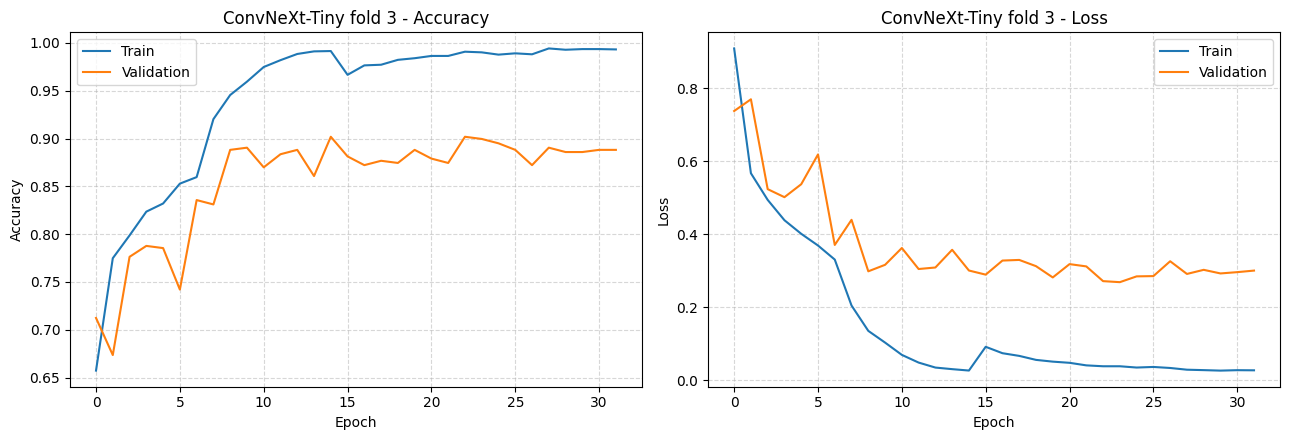

Fold 3 | Acc 0.9073 | F1 0.9066 | AUC 0.9908

ConvNeXt-Tiny - Fold 4/5
Train 3011 | inner validation 415 | held-out test 832

Stage 1/3: frozen backbone (head only)
Epoch 1/6
95/95 - 61s - loss: 0.8774 - accuracy: 0.6626 - val_loss: 0.7775 - val_accuracy: 0.6916 - lr: 0.0010 - 61s/epoch - 641ms/step
Epoch 2/6
95/95 - 30s - loss: 0.5740 - accuracy: 0.7682 - val_loss: 0.4461 - val_accuracy: 0.8361 - lr: 0.0010 - 30s/epoch - 317ms/step
Epoch 3/6
95/95 - 30s - loss: 0.5012 - accuracy: 0.7984 - val_loss: 0.4333 - val_accuracy: 0.8434 - lr: 0.0010 - 30s/epoch - 313ms/step
Epoch 4/6
95/95 - 29s - loss: 0.4404 - accuracy: 0.8263 - val_loss: 0.4349 - val_accuracy: 0.8313 - lr: 0.0010 - 29s/epoch - 304ms/step
Epoch 5/6
95/95 - 29s - loss: 0.4134 - accuracy: 0.8333 - val_loss: 0.5539 - val_accuracy: 0.7446 - lr: 0.0010 - 29s/epoch - 306ms/step
Epoch 6/6
95/95 - 30s - loss: 0.4011 - accuracy: 0.8270 - val_loss: 0.4014 - val_accuracy: 0.8313 - lr: 0.0010 - 30s/epoch - 315ms/step

Stage 2/3: fine-tu

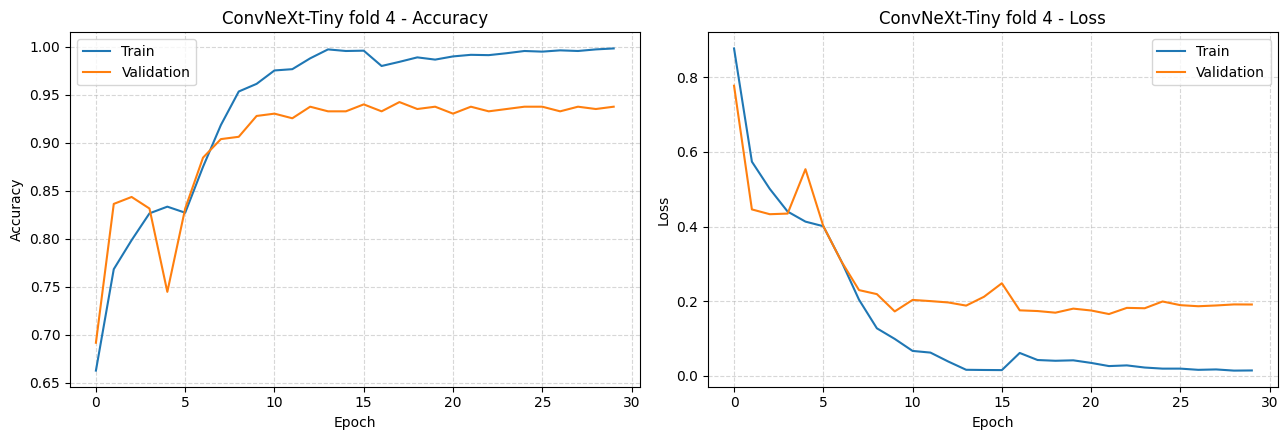

Fold 4 | Acc 0.9291 | F1 0.9286 | AUC 0.9925

ConvNeXt-Tiny - Fold 5/5
Train 2948 | inner validation 441 | held-out test 869

Stage 1/3: frozen backbone (head only)
Epoch 1/6
93/93 - 61s - loss: 0.8943 - accuracy: 0.6567 - val_loss: 0.6202 - val_accuracy: 0.7619 - lr: 0.0010 - 61s/epoch - 655ms/step
Epoch 2/6
93/93 - 30s - loss: 0.5588 - accuracy: 0.7731 - val_loss: 0.5507 - val_accuracy: 0.7778 - lr: 0.0010 - 30s/epoch - 320ms/step
Epoch 3/6
93/93 - 29s - loss: 0.4658 - accuracy: 0.8083 - val_loss: 0.4632 - val_accuracy: 0.7914 - lr: 0.0010 - 29s/epoch - 315ms/step
Epoch 4/6
93/93 - 30s - loss: 0.4243 - accuracy: 0.8243 - val_loss: 0.4371 - val_accuracy: 0.8186 - lr: 0.0010 - 30s/epoch - 317ms/step
Epoch 5/6
93/93 - 29s - loss: 0.4072 - accuracy: 0.8277 - val_loss: 0.4268 - val_accuracy: 0.8299 - lr: 0.0010 - 29s/epoch - 317ms/step
Epoch 6/6
93/93 - 29s - loss: 0.3852 - accuracy: 0.8396 - val_loss: 0.5092 - val_accuracy: 0.7506 - lr: 0.0010 - 29s/epoch - 309ms/step

Stage 2/3: fine-tu

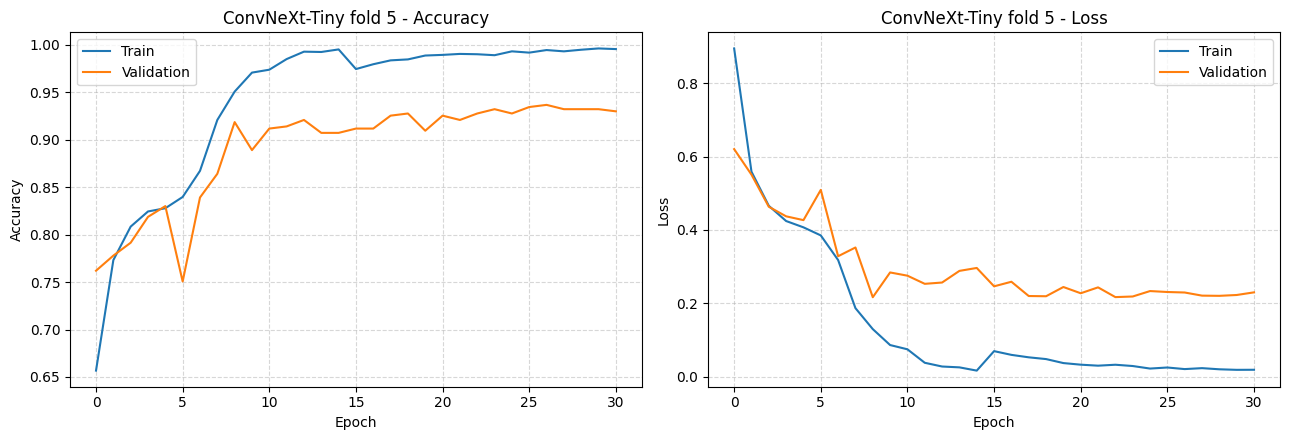

Fold 5 | Acc 0.8861 | F1 0.8825 | AUC 0.9854

ConvNeXt-Tiny summary (mean +/- SD over 5 folds)
  Accuracy              : 0.9112 +/- 0.0160
  Precision (macro)     : 0.9124 +/- 0.0167
  Recall (macro)        : 0.9074 +/- 0.0180
  F1 (macro)            : 0.9089 +/- 0.0169
  F1 (weighted)         : 0.9112 +/- 0.0163
  ROC-AUC (macro OvR)   : 0.9905 +/- 0.0029


,Model,Fold,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),ROC-AUC (macro OvR),Train images,Validation images,Test images,Epochs run,Best inner val loss,Train time (min)
0,ConvNeXt-Tiny,1,0.917153,0.916978,0.908985,0.912305,0.917078,0.991484,2982,419,857,27,0.364500,21.599928
1,ConvNeXt-Tiny,2,0.916564,0.915289,0.918115,0.914477,0.916980,0.992250,3004,439,815,30,0.316115,24.858443
2,ConvNeXt-Tiny,3,0.907345,0.912679,0.902431,0.906601,0.906380,0.990828,2935,438,885,32,0.268520,26.588675
3,ConvNeXt-Tiny,4,0.929087,0.931454,0.927399,0.928635,0.929504,0.992543,3011,415,832,30,0.165808,24.950173
4,ConvNeXt-Tiny,5,0.886076,0.885392,0.879937,0.882471,0.886000,0.985449,2948,441,869,31,0.216852,25.712584


In [12]:
train_and_evaluate('ConvNeXt-Tiny')

### 9.2 MobileNetV3-Large


Model: MobileNetV3-Large | Stratified group 5-fold CV | inner validation 12.5%

MobileNetV3-Large - Fold 1/5
Train 2982 | inner validation 419 | held-out test 857

Stage 1/3: frozen backbone (head only)
Epoch 1/6
94/94 - 24s - loss: 0.9712 - accuracy: 0.6405 - val_loss: 0.6317 - val_accuracy: 0.7279 - lr: 0.0010 - 24s/epoch - 252ms/step
Epoch 2/6
94/94 - 8s - loss: 0.5717 - accuracy: 0.7710 - val_loss: 0.6325 - val_accuracy: 0.7446 - lr: 0.0010 - 8s/epoch - 87ms/step
Epoch 3/6
94/94 - 8s - loss: 0.4733 - accuracy: 0.8115 - val_loss: 0.6425 - val_accuracy: 0.7613 - lr: 0.0010 - 8s/epoch - 87ms/step
Epoch 4/6
94/94 - 9s - loss: 0.4610 - accuracy: 0.8162 - val_loss: 0.5570 - val_accuracy: 0.7757 - lr: 0.0010 - 9s/epoch - 99ms/step
Epoch 5/6
94/94 - 8s - loss: 0.4092 - accuracy: 0.8307 - val_loss: 0.6195 - val_accuracy: 0.7828 - lr: 0.0010 - 8s/epoch - 87ms/step
Epoch 6/6
94/94 - 8s - loss: 0.3851 - accuracy: 0.8457 - val_loss: 0.5832 - val_accuracy: 0.7685 - lr: 0.0010 - 8s/epoch - 86ms/

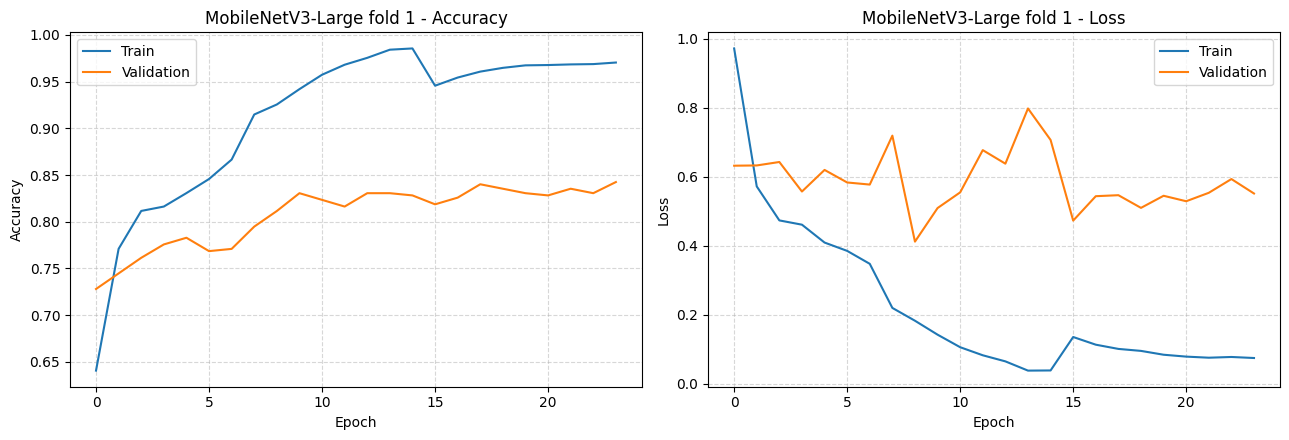

Fold 1 | Acc 0.8658 | F1 0.8697 | AUC 0.9841

MobileNetV3-Large - Fold 2/5
Train 3004 | inner validation 439 | held-out test 815

Stage 1/3: frozen backbone (head only)
Epoch 1/6
94/94 - 24s - loss: 0.9017 - accuracy: 0.6441 - val_loss: 0.7765 - val_accuracy: 0.6879 - lr: 0.0010 - 24s/epoch - 259ms/step
Epoch 2/6
94/94 - 8s - loss: 0.5700 - accuracy: 0.7683 - val_loss: 0.8901 - val_accuracy: 0.6469 - lr: 0.0010 - 8s/epoch - 84ms/step
Epoch 3/6
94/94 - 9s - loss: 0.5239 - accuracy: 0.7840 - val_loss: 0.7572 - val_accuracy: 0.6970 - lr: 0.0010 - 9s/epoch - 99ms/step
Epoch 4/6
94/94 - 9s - loss: 0.4728 - accuracy: 0.8049 - val_loss: 0.7361 - val_accuracy: 0.7175 - lr: 0.0010 - 9s/epoch - 99ms/step
Epoch 5/6
94/94 - 9s - loss: 0.4515 - accuracy: 0.8229 - val_loss: 0.6697 - val_accuracy: 0.7608 - lr: 0.0010 - 9s/epoch - 98ms/step
Epoch 6/6
94/94 - 8s - loss: 0.3782 - accuracy: 0.8399 - val_loss: 0.8255 - val_accuracy: 0.7130 - lr: 0.0010 - 8s/epoch - 86ms/step

Stage 2/3: fine-tune top 30 %

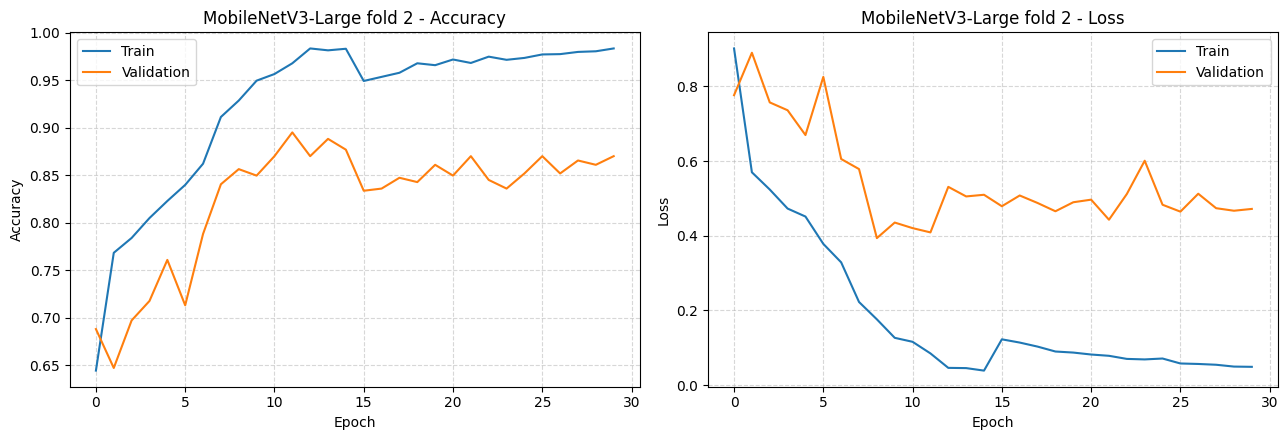

Fold 2 | Acc 0.8834 | F1 0.8876 | AUC 0.9862

MobileNetV3-Large - Fold 3/5
Train 2935 | inner validation 438 | held-out test 885

Stage 1/3: frozen backbone (head only)
Epoch 1/6
92/92 - 22s - loss: 0.9344 - accuracy: 0.6477 - val_loss: 0.7513 - val_accuracy: 0.6872 - lr: 0.0010 - 22s/epoch - 243ms/step
Epoch 2/6
92/92 - 8s - loss: 0.5938 - accuracy: 0.7540 - val_loss: 0.9115 - val_accuracy: 0.6370 - lr: 0.0010 - 8s/epoch - 87ms/step
Epoch 3/6
92/92 - 8s - loss: 0.4980 - accuracy: 0.8003 - val_loss: 0.7648 - val_accuracy: 0.6918 - lr: 0.0010 - 8s/epoch - 87ms/step
Epoch 4/6
92/92 - 9s - loss: 0.4515 - accuracy: 0.8164 - val_loss: 0.7056 - val_accuracy: 0.7237 - lr: 0.0010 - 9s/epoch - 99ms/step
Epoch 5/6
92/92 - 9s - loss: 0.4178 - accuracy: 0.8327 - val_loss: 0.6865 - val_accuracy: 0.7329 - lr: 0.0010 - 9s/epoch - 99ms/step
Epoch 6/6
92/92 - 8s - loss: 0.4108 - accuracy: 0.8385 - val_loss: 1.0452 - val_accuracy: 0.6575 - lr: 0.0010 - 8s/epoch - 88ms/step

Stage 2/3: fine-tune top 30 %

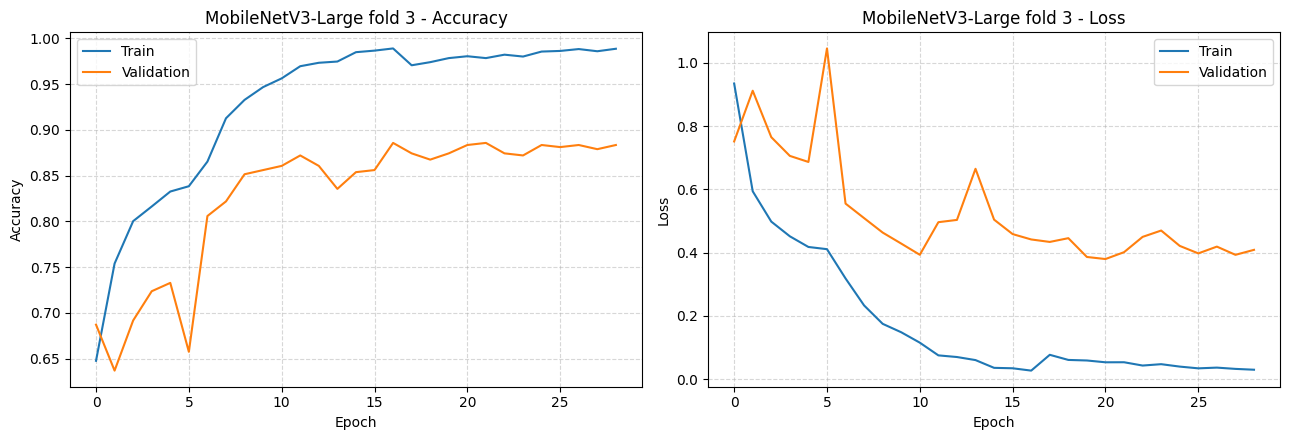

Fold 3 | Acc 0.8983 | F1 0.8920 | AUC 0.9865

MobileNetV3-Large - Fold 4/5
Train 3011 | inner validation 415 | held-out test 832

Stage 1/3: frozen backbone (head only)
Epoch 1/6
95/95 - 23s - loss: 0.9746 - accuracy: 0.6337 - val_loss: 0.8528 - val_accuracy: 0.6892 - lr: 0.0010 - 23s/epoch - 241ms/step
Epoch 2/6
95/95 - 9s - loss: 0.6125 - accuracy: 0.7675 - val_loss: 0.7505 - val_accuracy: 0.7036 - lr: 0.0010 - 9s/epoch - 98ms/step
Epoch 3/6
95/95 - 9s - loss: 0.5321 - accuracy: 0.7894 - val_loss: 0.6731 - val_accuracy: 0.7108 - lr: 0.0010 - 9s/epoch - 98ms/step
Epoch 4/6
95/95 - 9s - loss: 0.4882 - accuracy: 0.8054 - val_loss: 0.5819 - val_accuracy: 0.7904 - lr: 0.0010 - 9s/epoch - 98ms/step
Epoch 5/6
95/95 - 8s - loss: 0.4438 - accuracy: 0.8260 - val_loss: 0.6347 - val_accuracy: 0.7735 - lr: 0.0010 - 8s/epoch - 86ms/step
Epoch 6/6
95/95 - 10s - loss: 0.4411 - accuracy: 0.8263 - val_loss: 0.5050 - val_accuracy: 0.8265 - lr: 0.0010 - 10s/epoch - 106ms/step

Stage 2/3: fine-tune top 3

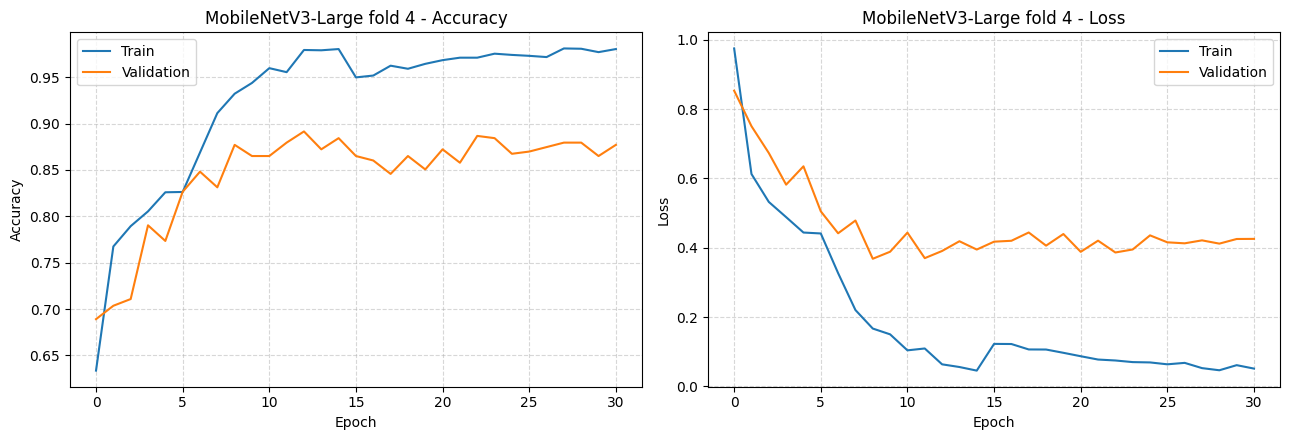

Fold 4 | Acc 0.8714 | F1 0.8687 | AUC 0.9855

MobileNetV3-Large - Fold 5/5
Train 2948 | inner validation 441 | held-out test 869

Stage 1/3: frozen backbone (head only)
Epoch 1/6
93/93 - 24s - loss: 0.9408 - accuracy: 0.6401 - val_loss: 0.6555 - val_accuracy: 0.7324 - lr: 0.0010 - 24s/epoch - 262ms/step
Epoch 2/6
93/93 - 9s - loss: 0.5803 - accuracy: 0.7693 - val_loss: 0.6305 - val_accuracy: 0.7710 - lr: 0.0010 - 9s/epoch - 99ms/step
Epoch 3/6
93/93 - 8s - loss: 0.5035 - accuracy: 0.7832 - val_loss: 0.6507 - val_accuracy: 0.7438 - lr: 0.0010 - 8s/epoch - 89ms/step
Epoch 4/6
93/93 - 9s - loss: 0.4473 - accuracy: 0.8192 - val_loss: 0.5482 - val_accuracy: 0.7710 - lr: 0.0010 - 9s/epoch - 100ms/step
Epoch 5/6
93/93 - 9s - loss: 0.4330 - accuracy: 0.8209 - val_loss: 0.4577 - val_accuracy: 0.8277 - lr: 0.0010 - 9s/epoch - 98ms/step
Epoch 6/6
93/93 - 8s - loss: 0.3971 - accuracy: 0.8314 - val_loss: 0.6485 - val_accuracy: 0.7234 - lr: 0.0010 - 8s/epoch - 86ms/step

Stage 2/3: fine-tune top 30 

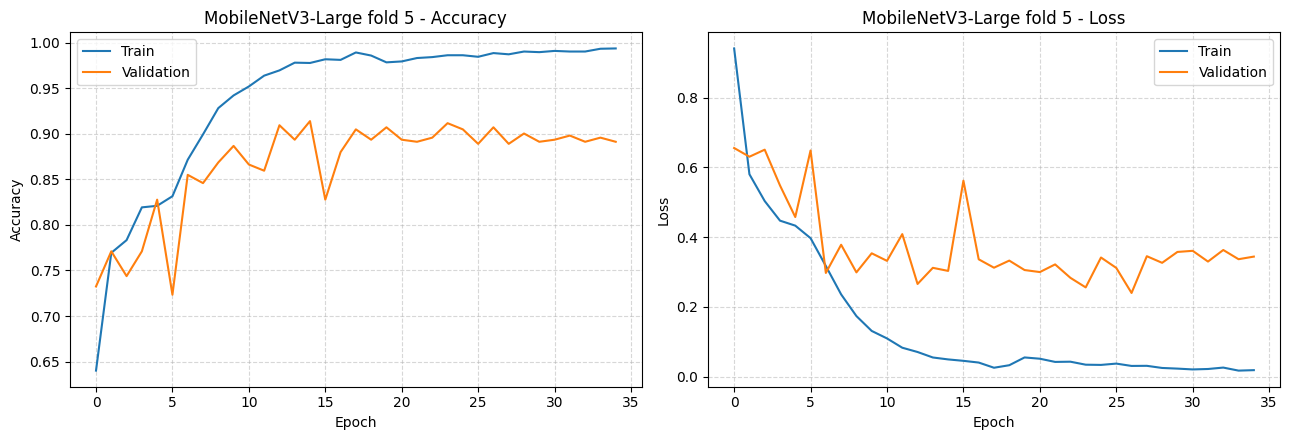

Fold 5 | Acc 0.8757 | F1 0.8701 | AUC 0.9797

MobileNetV3-Large summary (mean +/- SD over 5 folds)
  Accuracy              : 0.8789 +/- 0.0126
  Precision (macro)     : 0.8846 +/- 0.0104
  Recall (macro)        : 0.8792 +/- 0.0163
  F1 (macro)            : 0.8776 +/- 0.0112
  F1 (weighted)         : 0.8791 +/- 0.0132
  ROC-AUC (macro OvR)   : 0.9844 +/- 0.0028


,Model,Fold,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),ROC-AUC (macro OvR),Train images,Validation images,Test images,Epochs run,Best inner val loss,Train time (min)
0,MobileNetV3-Large,1,0.865811,0.869197,0.878554,0.869678,0.862532,0.984071,2982,419,857,24,0.411929,5.603311
1,MobileNetV3-Large,2,0.883436,0.894174,0.888555,0.887597,0.886363,0.986165,3004,439,815,30,0.393728,6.948581
2,MobileNetV3-Large,3,0.898305,0.886148,0.900560,0.892024,0.897149,0.986544,2935,438,885,29,0.379664,6.613393
3,MobileNetV3-Large,4,0.871394,0.879958,0.870287,0.868683,0.873458,0.985479,3011,415,832,31,0.368163,7.074903
4,MobileNetV3-Large,5,0.875719,0.893734,0.858140,0.870125,0.876053,0.979657,2948,441,869,35,0.240048,7.823009


In [13]:
train_and_evaluate('MobileNetV3-Large')

## 10. Results Aggregation (Method Validation)

### 10.1 Fold-wise and mean ± SD tables

Fold-wise results (held-out fold only)


,Model,Fold,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),ROC-AUC (macro OvR),Epochs run,Train time (min)
0,ConvNeXt-Tiny,1,0.9172,0.9170,0.9090,0.9123,0.9171,0.9915,27,21.5999
1,ConvNeXt-Tiny,2,0.9166,0.9153,0.9181,0.9145,0.9170,0.9923,30,24.8584
2,ConvNeXt-Tiny,3,0.9073,0.9127,0.9024,0.9066,0.9064,0.9908,32,26.5887
3,ConvNeXt-Tiny,4,0.9291,0.9315,0.9274,0.9286,0.9295,0.9925,30,24.9502
4,ConvNeXt-Tiny,5,0.8861,0.8854,0.8799,0.8825,0.8860,0.9854,31,25.7126
5,MobileNetV3-Large,1,0.8658,0.8692,0.8786,0.8697,0.8625,0.9841,24,5.6033
6,MobileNetV3-Large,2,0.8834,0.8942,0.8886,0.8876,0.8864,0.9862,30,6.9486
7,MobileNetV3-Large,3,0.8983,0.8861,0.9006,0.8920,0.8971,0.9865,29,6.6134
8,MobileNetV3-Large,4,0.8714,0.8800,0.8703,0.8687,0.8735,0.9855,31,7.0749
9,MobileNetV3-Large,5,0.8757,0.8937,0.8581,0.8701,0.8761,0.9797,35,7.8230



Mean ± SD over 5 folds (%)


,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),ROC-AUC (macro OvR)
Model,,,,,,
ConvNeXt-Tiny,91.12 ± 1.60,91.24 ± 1.67,90.74 ± 1.80,90.89 ± 1.69,91.12 ± 1.63,99.05 ± 0.29
MobileNetV3-Large,87.89 ± 1.26,88.46 ± 1.04,87.92 ± 1.63,87.76 ± 1.12,87.91 ± 1.32,98.44 ± 0.28


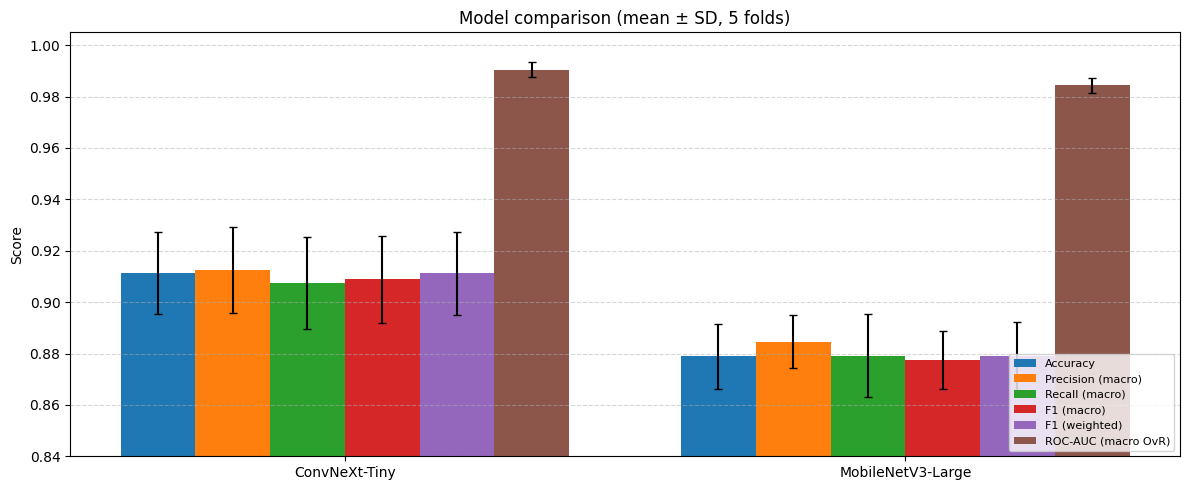

In [14]:
fold_tables = {m: pd.read_csv(os.path.join(RESULTS_DIR, f'{m}_5fold_metrics.csv')) for m in MODEL_NAMES}

all_folds = pd.concat(fold_tables.values(), ignore_index=True)
all_folds.to_csv(os.path.join(RESULTS_DIR, 'all_fold_metrics.csv'), index=False)

print('Fold-wise results (held-out fold only)')
display(all_folds[['Model', 'Fold'] + METRIC_COLS + ['Epochs run', 'Train time (min)']].round(4))

rows, pretty = [], []
for m in MODEL_NAMES:
    df = fold_tables[m]
    r = {'Model': m}
    p = {'Model': m}
    for c in METRIC_COLS:
        r[f'{c} mean'], r[f'{c} std'] = df[c].mean(), df[c].std(ddof=1)
        p[c] = f"{df[c].mean() * 100:.2f} ± {df[c].std(ddof=1) * 100:.2f}"
    r['Train time / fold (min)'] = df['Train time (min)'].mean()
    rows.append(r); pretty.append(p)

summary_numeric = pd.DataFrame(rows).set_index('Model')
summary_pretty = pd.DataFrame(pretty).set_index('Model')
summary_numeric.to_csv(os.path.join(RESULTS_DIR, 'model_comparison_numeric.csv'))
summary_pretty.to_csv(os.path.join(RESULTS_DIR, 'model_comparison_mean_std.csv'))
print('\nMean ± SD over 5 folds (%)')
display(summary_pretty)

fig, ax = plt.subplots(figsize=(12, 5))
width = 0.8 / len(METRIC_COLS)
for k, c in enumerate(METRIC_COLS):
    means = [summary_numeric.loc[m, f'{c} mean'] for m in MODEL_NAMES]
    stds = [summary_numeric.loc[m, f'{c} std'] for m in MODEL_NAMES]
    ax.bar(np.arange(len(MODEL_NAMES)) + k * width, means, width, yerr=stds, capsize=3, label=c)
ax.set_xticks(np.arange(len(MODEL_NAMES)) + width * (len(METRIC_COLS) - 1) / 2)
ax.set_xticklabels(MODEL_NAMES)
low = min(summary_numeric[f'{c} mean'].min() - summary_numeric[f'{c} std'].max() for c in METRIC_COLS)
ax.set_ylim(max(0.0, np.floor(low * 50) / 50 - 0.02), 1.005); ax.set_ylabel('Score')
ax.set_title('Model comparison (mean ± SD, 5 folds)')
ax.legend(loc='lower right', fontsize=8); ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'model_comparison_chart.png'), dpi=300)
plt.show()

### 10.2 Per-class precision, recall and F1 (mean ± SD over folds)

In [15]:
def load_reports(model_name, results_dir=RESULTS_DIR):
    return [pd.read_csv(os.path.join(results_dir, f'{model_name}_fold{f}_classification_report.csv'), index_col=0)
            for f in range(1, N_SPLITS + 1)]


per_class_rows = []
for m in MODEL_NAMES:
    reps = load_reports(m)
    for cls in CLASS_NAMES:
        row = {'Model': m, 'Class': cls}
        for col, name in [('precision', 'Precision'), ('recall', 'Recall'), ('f1-score', 'F1-score')]:
            vals = np.array([r.loc[cls, col] for r in reps])
            row[name] = f'{vals.mean() * 100:.2f} ± {vals.std(ddof=1) * 100:.2f}'
        row['Support (all folds)'] = int(sum(r.loc[cls, 'support'] for r in reps))
        per_class_rows.append(row)

df_per_class = pd.DataFrame(per_class_rows)
df_per_class.to_csv(os.path.join(RESULTS_DIR, 'per_class_metrics_mean_std.csv'), index=False)
for m in MODEL_NAMES:
    print(f'\n{m}')
    display(df_per_class[df_per_class.Model == m].drop(columns='Model').reset_index(drop=True))


ConvNeXt-Tiny


,Class,Precision,Recall,F1-score,Support (all folds)
0,Fruit_Rot,100.00 ± 0.00,98.85 ± 2.58,99.41 ± 1.33,257
1,Healthy_Leaf,90.59 ± 3.95,91.58 ± 2.40,91.01 ± 1.58,1065
2,Insects_Eaten_Leaf,81.24 ± 3.95,79.52 ± 6.83,80.27 ± 4.54,744
3,Leaf_Curl,94.87 ± 6.28,87.96 ± 5.28,91.28 ± 5.70,531
4,Leaf_Spot,82.60 ± 5.19,87.34 ± 3.82,84.74 ± 2.03,479
5,Yellow_Vein_Mosaic_Virus,98.11 ± 1.27,99.17 ± 1.02,98.63 ± 0.69,1182



MobileNetV3-Large


,Class,Precision,Recall,F1-score,Support (all folds)
0,Fruit_Rot,97.34 ± 4.08,100.00 ± 0.00,98.62 ± 2.13,257
1,Healthy_Leaf,90.57 ± 3.04,84.05 ± 5.16,87.06 ± 2.09,1065
2,Insects_Eaten_Leaf,72.85 ± 7.19,75.84 ± 7.93,73.71 ± 1.26,744
3,Leaf_Curl,96.05 ± 3.73,84.03 ± 7.98,89.38 ± 4.05,531
4,Leaf_Spot,77.51 ± 7.30,84.02 ± 11.59,79.84 ± 4.74,479
5,Yellow_Vein_Mosaic_Virus,96.46 ± 3.73,99.59 ± 0.49,97.97 ± 1.91,1182


### 10.3 Aggregated confusion matrices (out-of-fold predictions)

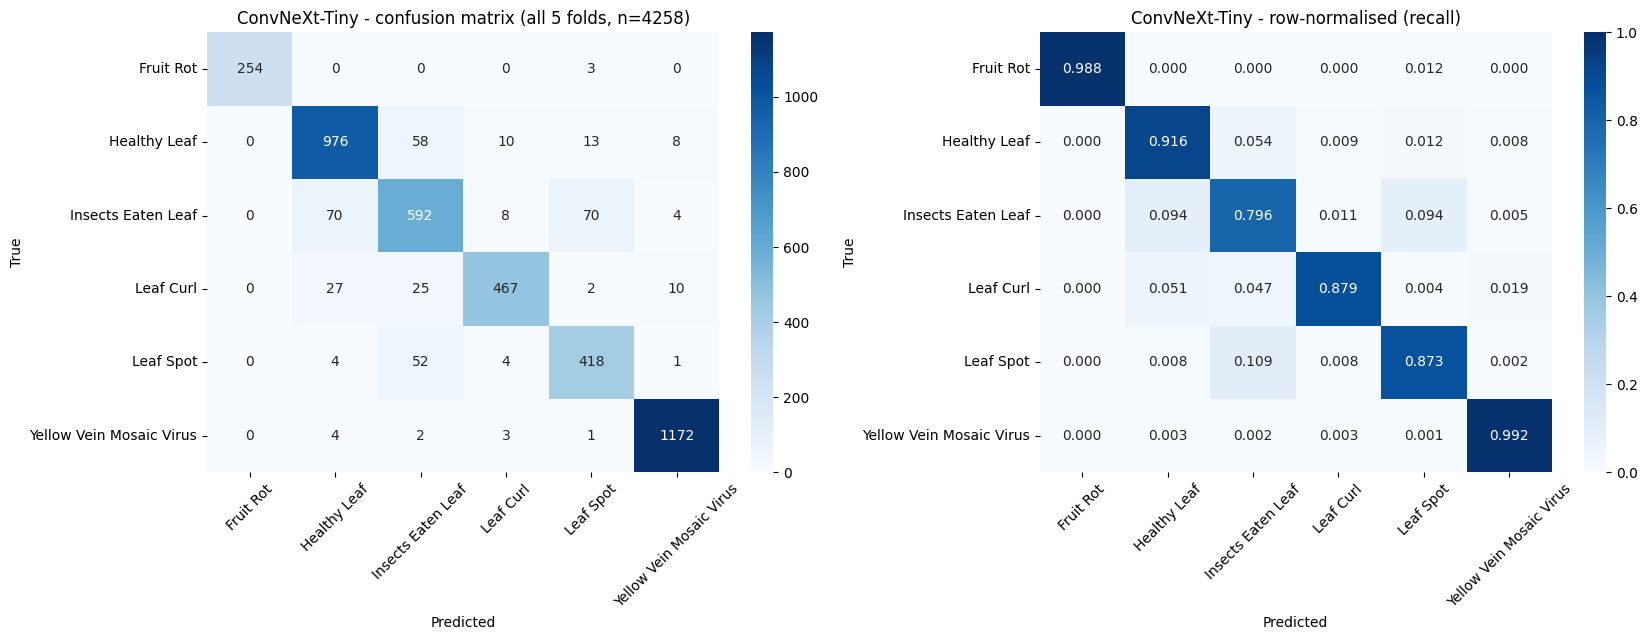

ConvNeXt-Tiny - top confusions (true -> predicted, count): [('Insects Eaten Leaf', 'Healthy Leaf', 70), ('Insects Eaten Leaf', 'Leaf Spot', 70), ('Healthy Leaf', 'Insects Eaten Leaf', 58), ('Leaf Spot', 'Insects Eaten Leaf', 52), ('Leaf Curl', 'Healthy Leaf', 27)]


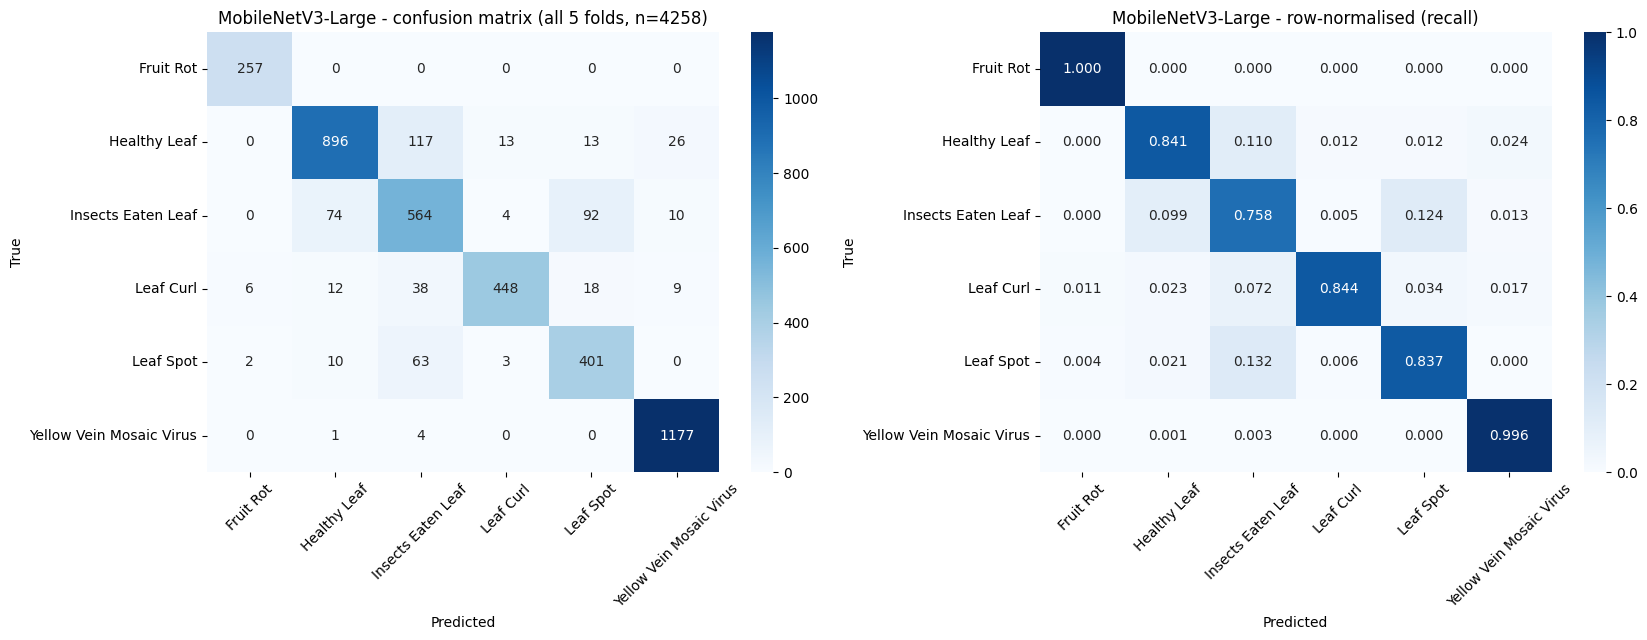

MobileNetV3-Large - top confusions (true -> predicted, count): [('Healthy Leaf', 'Insects Eaten Leaf', 117), ('Insects Eaten Leaf', 'Leaf Spot', 92), ('Insects Eaten Leaf', 'Healthy Leaf', 74), ('Leaf Spot', 'Insects Eaten Leaf', 63), ('Leaf Curl', 'Insects Eaten Leaf', 38)]


In [16]:
def load_oof(model_name):
    frames = []
    for f in range(1, N_SPLITS + 1):
        d = pd.read_csv(fold_paths(model_name, f)['preds'])
        d['Fold'] = f
        frames.append(d)
    return pd.concat(frames, ignore_index=True)


oof = {m: load_oof(m) for m in MODEL_NAMES}
short = [c.replace('_', ' ') for c in CLASS_NAMES]

for m in MODEL_NAMES:
    cm = confusion_matrix(oof[m]['true'], oof[m]['pred'], labels=np.arange(NUM_CLASSES))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=short, yticklabels=short, ax=axes[0])
    axes[0].set_title(f'{m} - confusion matrix (all 5 folds, n={len(oof[m])})')
    sns.heatmap(cm_norm, annot=True, fmt='.3f', cmap='Blues', xticklabels=short, yticklabels=short, ax=axes[1], vmin=0, vmax=1)
    axes[1].set_title(f'{m} - row-normalised (recall)')
    for ax in axes:
        ax.set_xlabel('Predicted'); ax.set_ylabel('True')
        ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, f'{m}_confusion_matrix_aggregated.png'), dpi=300)
    plt.show()

    off = [(short[i], short[j], int(cm[i, j])) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
    off.sort(key=lambda t: -t[2])
    print(f'{m} - top confusions (true -> predicted, count):', off[:5])

### 10.4 Aggregated ROC curves (one-vs-rest, out-of-fold)

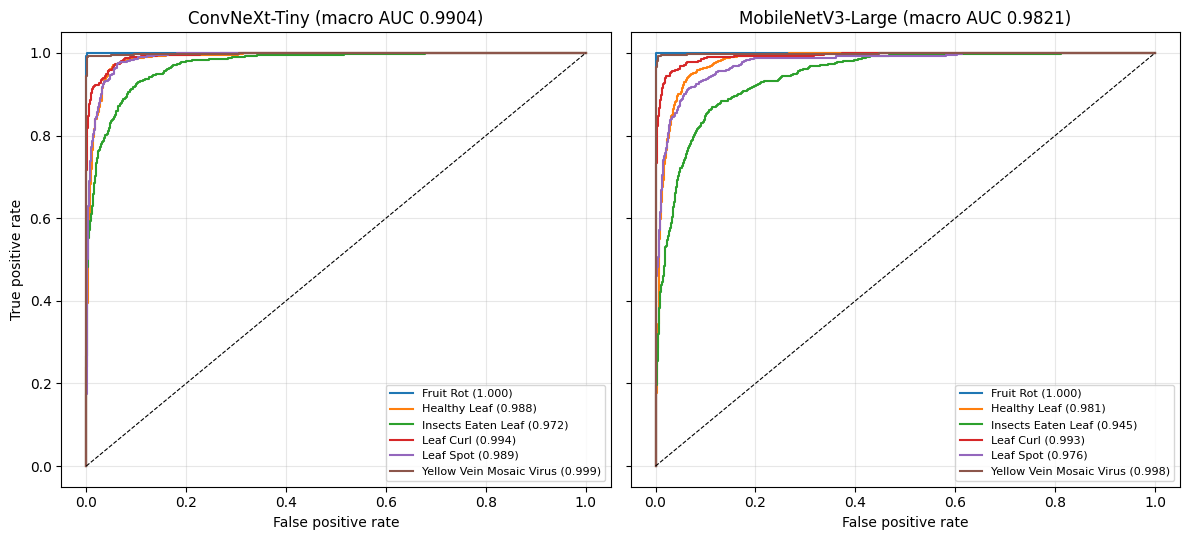

,Fruit_Rot,Healthy_Leaf,Insects_Eaten_Leaf,Leaf_Curl,Leaf_Spot,Yellow_Vein_Mosaic_Virus,Macro AUC
Model,,,,,,,
ConvNeXt-Tiny,1.0,0.9882,0.9719,0.9941,0.9894,0.9987,0.9904
MobileNetV3-Large,1.0,0.9814,0.9447,0.9927,0.9756,0.9982,0.9821


In [17]:
auc_rows = []
fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(6 * len(MODEL_NAMES), 5.5), sharey=True)
for ax, m in zip(axes, MODEL_NAMES):
    d = oof[m]
    y_bin = label_binarize(d['true'], classes=np.arange(NUM_CLASSES))
    probs = d[[f'p_{c}' for c in CLASS_NAMES]].to_numpy()
    row = {'Model': m}
    for i, cls in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
        a = auc(fpr, tpr)
        row[cls] = round(a, 4)
        ax.plot(fpr, tpr, label=f'{short[i]} ({a:.3f})')
    row['Macro AUC'] = round(np.mean([row[c] for c in CLASS_NAMES]), 4)
    auc_rows.append(row)
    ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
    ax.set_title(f'{m} (macro AUC {row["Macro AUC"]:.4f})')
    ax.set_xlabel('False positive rate'); ax.legend(loc='lower right', fontsize=8)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('True positive rate')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'roc_curves_aggregated.png'), dpi=300)
plt.show()

df_auc = pd.DataFrame(auc_rows).set_index('Model')
df_auc.to_csv(os.path.join(RESULTS_DIR, 'per_class_auc_aggregated.csv'))
display(df_auc)

### 10.5 Statistical comparison between models
The two models are evaluated on the **same folds**, so paired tests are used. With only 5 folds, p-values are indicative:
the plain paired t-test is optimistic because fold training sets overlap, so the Nadeau-Bengio corrected t-test is also
reported, and the minimum possible two-sided p of an exact Wilcoxon test with n = 5 is 0.0625.

In [18]:
def nadeau_bengio(d, n_train, n_test):
    k = len(d)
    var = d.var(ddof=1)
    if var == 0:
        return np.nan, np.nan
    t = d.mean() / np.sqrt((1.0 / k + n_test / n_train) * var)
    return t, 2 * stats.t.sf(abs(t), k - 1)


def paired_tests(tables, names, n_train, n_test, metrics=('Accuracy', 'F1 (macro)', 'ROC-AUC (macro OvR)')):
    out = []
    for metric in metrics:
        for a, b in itertools.combinations(names, 2):
            xa = tables[a].sort_values('Fold')[metric].to_numpy()
            xb = tables[b].sort_values('Fold')[metric].to_numpy()
            d = xa - xb
            t_p = stats.ttest_rel(xa, xb)
            _, p_nb = nadeau_bengio(d, n_train, n_test)
            try:
                p_w = stats.wilcoxon(xa, xb).pvalue
            except ValueError:
                p_w = np.nan
            out.append({
                'Metric': metric, 'Model A': a, 'Model B': b,
                'Mean diff (A-B)': d.mean(),
                'Paired t p-value': t_p.pvalue,
                'Corrected t p-value': p_nb,
                'Wilcoxon p-value': p_w,
                'A better on folds': f'{int((d > 0).sum())}/{len(d)}',
            })
    return pd.DataFrame(out)


ref = fold_tables[MODEL_NAMES[0]]
n_test_avg = ref['Test images'].mean()
n_train_avg = (ref['Train images'] + ref['Validation images']).mean()

df_tests = paired_tests(fold_tables, MODEL_NAMES, n_train_avg, n_test_avg)
df_tests.to_csv(os.path.join(RESULTS_DIR, 'statistical_tests.csv'), index=False)
display(df_tests.round(4))

,Metric,Model A,Model B,Mean diff (A-B),Paired t p-value,Corrected t p-value,Wilcoxon p-value,A better on folds
0,Accuracy,ConvNeXt-Tiny,MobileNetV3-Large,0.0323,0.0327,0.0993,0.0625,5/5
1,F1 (macro),ConvNeXt-Tiny,MobileNetV3-Large,0.0313,0.0252,0.0806,0.0625,5/5
2,ROC-AUC (macro OvR),ConvNeXt-Tiny,MobileNetV3-Large,0.0061,0.0004,0.0018,0.0625,5/5


## 11. Model Complexity and Speed
Latency and throughput use a compiled `tf.function` on one T4 with random input (model only, no image decoding).
`FP32 size` is the raw parameter size (params x 4 bytes); the `.weights.h5` checkpoint is about 3x larger because this format also stores the AdamW optimizer state (two moment estimates per trainable weight).

In [19]:
def best_fold_of(model_name):
    df = fold_tables[model_name]
    return int(df.loc[df['Accuracy'].idxmax(), 'Fold'])


def load_trained_model(model_name, fold):
    tf.keras.backend.clear_session()
    with tf.device('/GPU:0' if gpus else '/CPU:0'):
        model = BUILD_FNS[model_name]()
        model.load_weights(fold_paths(model_name, fold)['weights'])
    return model


def benchmark_model(model, n_latency=100, n_batches=20, batch=32):
    infer = tf.function(lambda x: model(x, training=False))
    x1 = tf.random.uniform((1,) + IMG_SIZE + (3,), 0, 255)
    for _ in range(10):
        infer(x1).numpy()
    t0 = time.perf_counter()
    for _ in range(n_latency):
        infer(x1).numpy()
    latency_ms = (time.perf_counter() - t0) / n_latency * 1000

    xb = tf.random.uniform((batch,) + IMG_SIZE + (3,), 0, 255)
    for _ in range(3):
        infer(xb).numpy()
    t0 = time.perf_counter()
    for _ in range(n_batches):
        infer(xb).numpy()
    throughput = batch * n_batches / (time.perf_counter() - t0)
    return latency_ms, throughput


cx_rows = []
for m in MODEL_NAMES:
    bf = best_fold_of(m)
    with tf.device('/GPU:0' if gpus else '/CPU:0'):
        model = load_trained_model(m, bf)
        lat, thr = benchmark_model(model)
    cx_rows.append({
        'Model': m,
        'Total parameters (M)': model.count_params() / 1e6,
        'FP32 size (MB)': model.count_params() * 4 / 1e6,
        'Weights file (MB)': os.path.getsize(fold_paths(m, bf)['weights']) / 1e6,
        'Latency, batch 1 (ms/img)': lat,
        'Throughput, batch 32 (img/s)': thr,
        'Training time / fold (min)': fold_tables[m]['Train time (min)'].mean(),
        'Epochs run / fold': fold_tables[m]['Epochs run'].mean(),
    })
    del model

df_cx = pd.DataFrame(cx_rows).set_index('Model')
df_cx.to_csv(os.path.join(RESULTS_DIR, 'model_complexity.csv'))
display(df_cx.round(3))
print('Benchmark device:', 'GPU (single T4)' if gpus else 'CPU', '| input', IMG_SIZE, '| compiled tf.function, random data.')

,Total parameters (M),FP32 size (MB),Weights file (MB),"Latency, batch 1 (ms/img)","Throughput, batch 32 (img/s)",Training time / fold (min),Epochs run / fold
Model,,,,,,,
ConvNeXt-Tiny,28.217,112.868,331.620,15.562,71.343,24.742,30.0
MobileNetV3-Large,3.491,13.966,41.963,5.826,526.519,6.813,29.8


Benchmark device: GPU (single T4) | input (320, 320) | compiled tf.function, random data.


## 12. Error Analysis (best model)

In [20]:
best_name = summary_numeric['Accuracy mean'].idxmax()
best_fold = best_fold_of(best_name)
print(f'Best model by mean accuracy: {best_name} | fold with highest accuracy: {best_fold}')

Best model by mean accuracy: ConvNeXt-Tiny | fold with highest accuracy: 4


### Misclassified examples (all folds, best model)

ConvNeXt-Tiny: 379 / 4258 images misclassified across the 5 held-out folds (8.90 %).


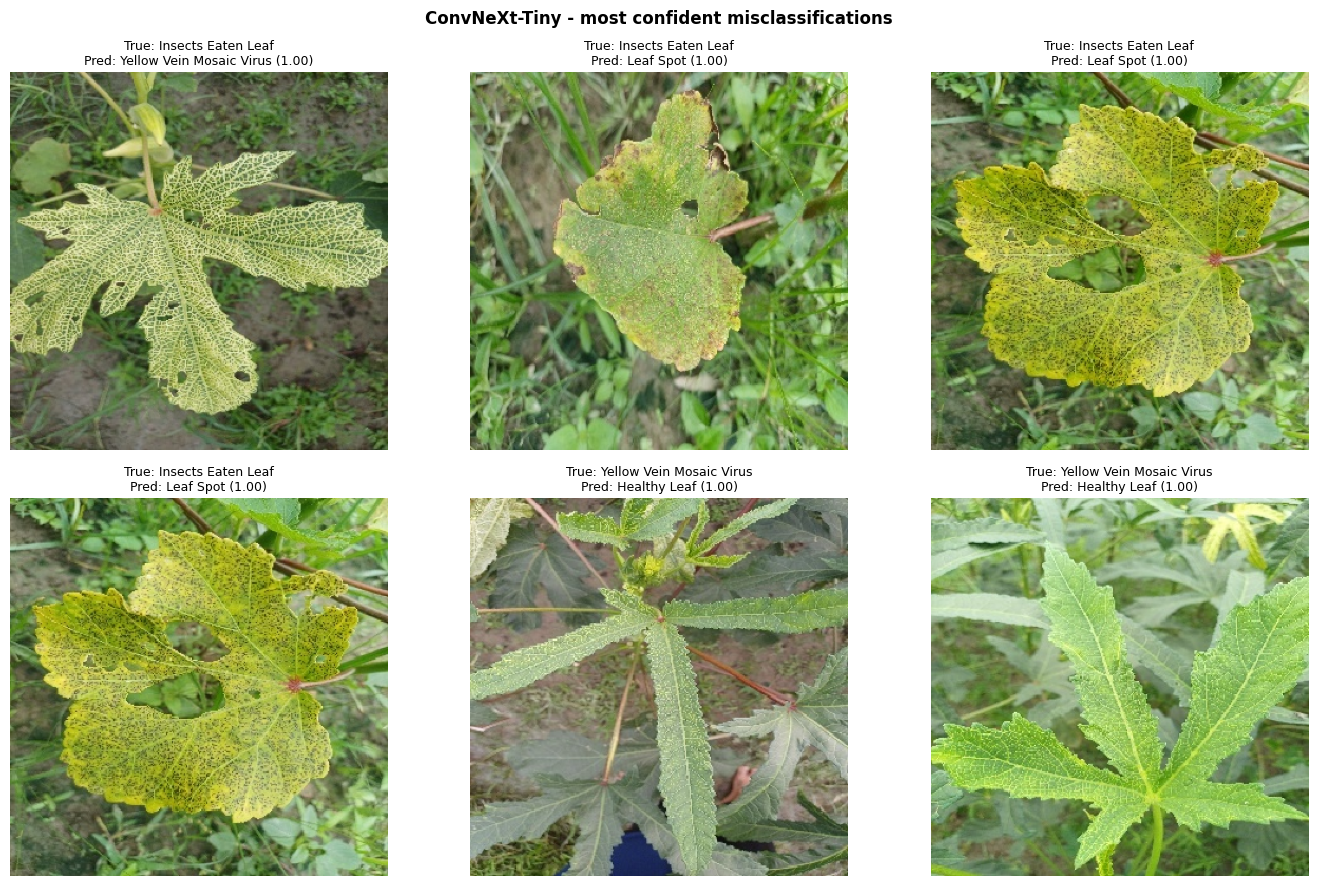

In [21]:
oof_best = oof[best_name].copy()
oof_best['confidence'] = oof_best[[f'p_{c}' for c in CLASS_NAMES]].max(axis=1)
wrong = oof_best[oof_best['true'] != oof_best['pred']].sort_values('confidence', ascending=False)
print(f'{best_name}: {len(wrong)} / {len(oof_best)} images misclassified across the 5 held-out folds '
      f'({len(wrong) / len(oof_best) * 100:.2f} %).')
wrong.assign(true_class=wrong['true'].map(lambda i: CLASS_NAMES[i]),
             pred_class=wrong['pred'].map(lambda i: CLASS_NAMES[i])
             )[['relative_path', 'true_class', 'pred_class', 'confidence', 'Fold']] \
     .to_csv(os.path.join(RESULTS_DIR, f'{best_name}_misclassified.csv'), index=False)

n_show = min(6, len(wrong))
if n_show:
    fig, axes = plt.subplots(2, 3, figsize=(14, 9))
    for ax in axes.flat:
        ax.axis('off')
    for ax, (_, r) in zip(axes.flat, wrong.head(n_show).iterrows()):
        ax.imshow(load_img(os.path.join(WORKING_DATASET, r['relative_path']), target_size=IMG_SIZE))
        ax.set_title(f"True: {short[int(r['true'])]}\nPred: {short[int(r['pred'])]} ({r['confidence']:.2f})", fontsize=9)
    plt.suptitle(f'{best_name} - most confident misclassifications', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, f'{best_name}_misclassified_examples.png'), dpi=300)
    plt.show()

## 13. Save Summary and Package Outputs

In [22]:
summary = {
    'models': MODEL_NAMES,
    'cross_validation': f'Stratified group {N_SPLITS}-fold (seed {SPLIT_SEED}; dHash near-duplicate groups, distance <= {NEAR_DUP_THRESHOLD})',
    'near_duplicate_groups': int(fold_manifest['group_id'].nunique()),
    'inner_validation_fraction': VAL_FRACTION,
    'images_after_cleaning': int(len(fold_manifest)),
    'cleaning': cleaning_stats,
    'classes': CLASS_NAMES,
    'best_model': best_name,
    'best_fold': best_fold,
    'results_mean': summary_numeric.round(5).to_dict(orient='index'),
    'environment': {'tensorflow': tf.__version__, 'gpus': [g.name for g in gpus]},
}
save_json_atomic(os.path.join(RESULTS_DIR, 'summary.json'), summary, indent=2)

archive = shutil.make_archive('/kaggle/working/okra_results_groupcv', 'zip', RESULTS_DIR)
print('Summary written. Results archive for download:', archive)
print('Saved output contents:', os.listdir('/kaggle/working'))
wsize = sum(os.path.getsize(os.path.join(MODEL_DIR, f)) for f in os.listdir(MODEL_DIR)) / 1e6
print(f'Model weights folder: {len(os.listdir(MODEL_DIR))} files, {wsize:.0f} MB')

Summary written. Results archive for download: /kaggle/working/okra_results_groupcv.zip
Saved output contents: ['okra_results_groupcv', '__notebook__.ipynb', 'okra_results_groupcv.zip', 'okra_models_groupcv']
Model weights folder: 10 files, 1717 MB


## 14. Cleanup (run last)
Deletes only the temporary dataset copy. Results and model weights are kept. Sections 11-12 need the dataset copy, so run this cell after they have finished.

In [23]:
shutil.rmtree(WORKING_DATASET, ignore_errors=True)   # weights and results are kept

for root in ('/kaggle/working', '/kaggle/temp'):
    if os.path.isdir(root):
        print(root, '->', os.listdir(root))

/kaggle/working -> ['okra_results_groupcv', '__notebook__.ipynb', 'okra_results_groupcv.zip', 'okra_models_groupcv']
/kaggle/temp -> []
